# WeatherVision: Computer Vision Assignments 1 and 2

**Author:** Rakhman Seidigali  
**Group:** SE-2411  
**Course:** Computer Vision, Astana IT University  
**Instructor:** Nurym Kaiyrkhan

This notebook runs the same source code as the local app: Simple CNN, MobileNetV2, ConvNeXt-Tiny, and an augmentation ablation. It classifies photographs as **Cloudy, Rain, Shine, or Sunrise**.

The experiments use the Multi-class Weather Dataset for Image Classification by Gbeminiyi Ajayi. Model metrics and figures are generated from the saved experiment outputs.

Choose **Runtime > Change runtime type > T4 GPU**, when available. A GPU is recommended. CPU fallback works but may take tens of minutes or longer. You can first run the isolated smoke test.

## 1. Load the project and install dependencies

Create the source archive locally with `python scripts/package_project.py`. Upload **WeatherVision_source.zip** in the next cell. The upload is extracted with path, symlink, member-size, and total-size checks. Existing project files are reused. You can also clone [the repository](https://github.com/commedeschamps/WeatherVision) and run this notebook from its project root.

In [1]:
from pathlib import Path, PurePosixPath
import os, stat, sys, subprocess, zipfile

PROJECT = Path('/content/WeatherVision') if Path('/content').exists() else Path.cwd()
if not (PROJECT / 'weather_cv.py').exists():
    from google.colab import files
    uploaded = files.upload()
    archives = [Path(name) for name in uploaded if name.endswith('.zip')]
    if len(archives) != 1:
        raise ValueError('Upload exactly one WeatherVision_source.zip archive.')
    with zipfile.ZipFile(archives[0]) as archive:
        total = 0
        for member in archive.infolist():
            name = PurePosixPath(member.filename)
            total += member.file_size
            if (name.is_absolute() or '..' in name.parts or chr(92) in member.filename
                or stat.S_ISLNK(member.external_attr >> 16)
                or member.file_size > 100_000_000 or total > 2_000_000_000):
                raise ValueError(f'Unsafe archive member: {member.filename}')
        archive.extractall(PROJECT)
os.chdir(PROJECT)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-dev.txt'], check=True)
os.environ['MPLCONFIGDIR'] = str(PROJECT / '.cache/matplotlib')
os.environ['TORCH_HOME'] = str(PROJECT / '.cache/torch')
print('Project:', PROJECT)

Project: /Users/rakhman/Desktop/assignment2-cv



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: /Users/rakhman/Desktop/assignment2-cv/.venv/bin/python -m pip install --upgrade pip


## 2. Check GPU and environment

In [2]:
import torch, torchvision
from src.utils import environment, select_device
print(environment())
print('Selected device:', select_device())
if not torch.cuda.is_available():
    print('CUDA unavailable. CPU/MPS fallback is supported; expect slower training.')

def cli(*args):
    subprocess.run([sys.executable, 'weather_cv.py', *map(str, args)], check=True)

{'python': '3.14.5', 'torch': '2.10.0', 'torchvision': '0.25.0', 'sklearn': '1.9.1', 'numpy': '2.5.4', 'platform': 'macOS-26.5.2-arm64-arm-64bit-Mach-O', 'processor': 'arm', 'cpu_count': 10, 'device': 'mps', 'cuda_available': False, 'mps_available': True, 'gpu': None, 'threads': 4}
Selected device: mps
CUDA unavailable. CPU/MPS fallback is supported; expect slower training.


## 3. Download, verify, deduplicate, and split the dataset

The project downloads the 224-square photographs from the pinned PerceptiLabs mirror. The preparation step validates images, removes exact duplicates, groups near duplicates, and assigns whole groups to approximately 70/15/15 splits using seed 42. Existing verified data are reused. All models share this manifest.

Dataset: Ajayi, G. (2018), *Multi-class Weather Dataset for Image Classification*, Mendeley Data, V1, [DOI 10.17632/4drtyfjtfy.1](https://doi.org/10.17632/4drtyfjtfy.1), CC BY 4.0. Mirror: [PerceptiLabs](https://github.com/PerceptiLabs/Weather-Analysis).

If automatic downloading fails, upload a dataset ZIP and set `LOCAL_DATASET_ZIP` to its path. A manual original archive may have different counts; train fresh runs with its manifest.

In [3]:
LOCAL_DATASET_ZIP = None  # e.g. '/content/Weather-Analysis-main.zip'
cli('prepare', *(['--local-zip', LOCAL_DATASET_ZIP] if LOCAL_DATASET_ZIP else []))
import json, pandas as pd
manifest = pd.read_csv('data/manifest.csv')
display(pd.crosstab(manifest.label, manifest.split, margins=True))
print(json.dumps(json.loads(Path('data/statistics.json').read_text()), indent=2))

Reusing verified manifest; --force explicitly rebuilds it.
split    test  train  val
label                    
cloudy     44    204   43
rain       31    143   31
shine      37    175   37
sunrise    53    246   53


split,test,train,val,All
label,,,,
cloudy,44,204,43,291
rain,31,143,31,205
shine,37,175,37,249
sunrise,53,246,53,352
All,165,768,164,1097


{
  "seed": 42,
  "valid_images_before_dedup": 1123,
  "corrupt_images": 0,
  "ignored_unrecognized_images": [
    "Weather-Analysis-ad78ac8fcf1b1aae229ca6e5310aa75b06783787/pl_logo.png"
  ],
  "retained_images": 1097,
  "exact_duplicates_removed": 26,
  "quarantined_conflicts": 0,
  "duplicate_pairs": 124,
  "near_duplicate_pairs": 97,
  "independent_groups": 1011,
  "counts": {
    "test": {
      "cloudy": 44,
      "rain": 31,
      "shine": 37,
      "sunrise": 53
    },
    "train": {
      "cloudy": 204,
      "rain": 143,
      "shine": 175,
      "sunrise": 246
    },
    "val": {
      "cloudy": 43,
      "rain": 31,
      "shine": 37,
      "sunrise": 53
    }
  },
  "manifest_sha256": "5d91854a3a40fe885abf72ed0723918160cc2ebd3b8dc0afd71285dde8d6c29e",
  "near_duplicate_rule": "pHash<=4 AND dHash<=4 AND abs(log(aspect ratio ratio))<=0.10 AND RGB thumbnail RMSE<=0.12",
  "limitations": "Detected duplicate components cannot cross splits. Conservative hashes can miss transforme

## 4. Inspect data and preprocessing

Inspection figures use training photographs. Review `data/duplicate_pairs.csv` before experimentation. Detected components are assigned to a single split, and the candidate pairs are saved for inspection. ImageNet normalization is shared; inference uses official V1 resize sizes (MobileNet 256, ConvNeXt 236) and a 224 center crop. Training-only augmentation adds horizontal flips, rotation up to 8 degrees, and mild color jitter. Validation/test transforms are deterministic.

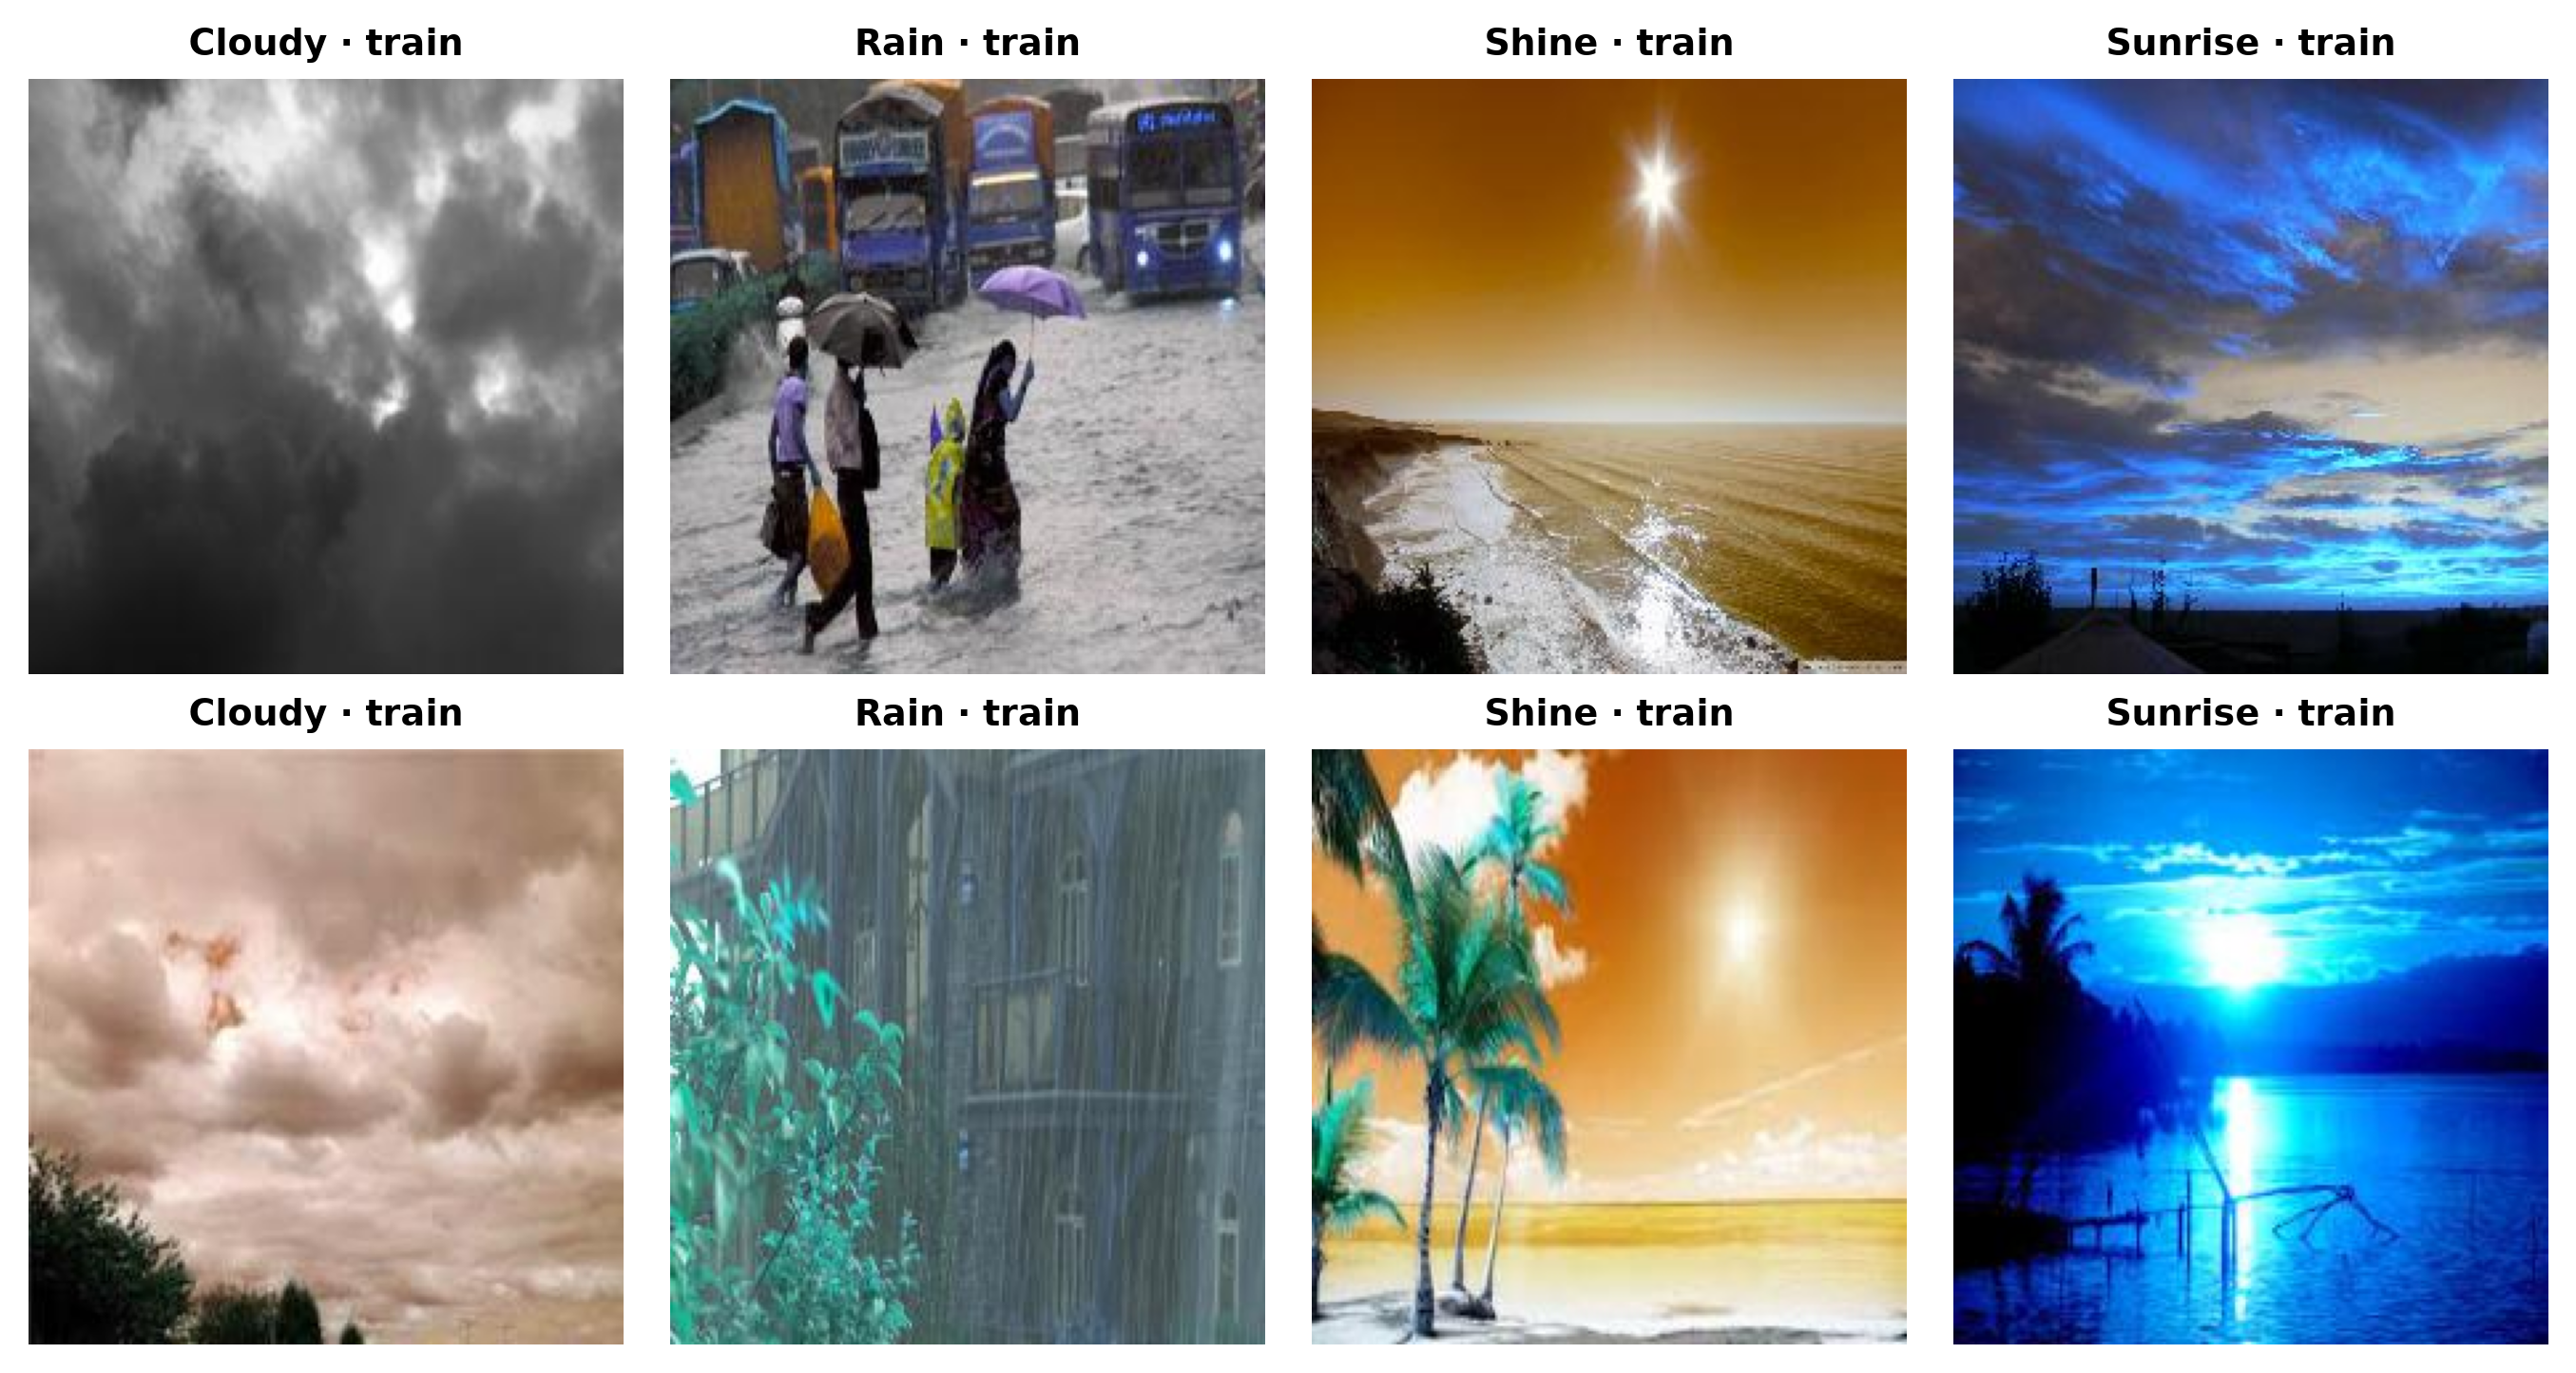

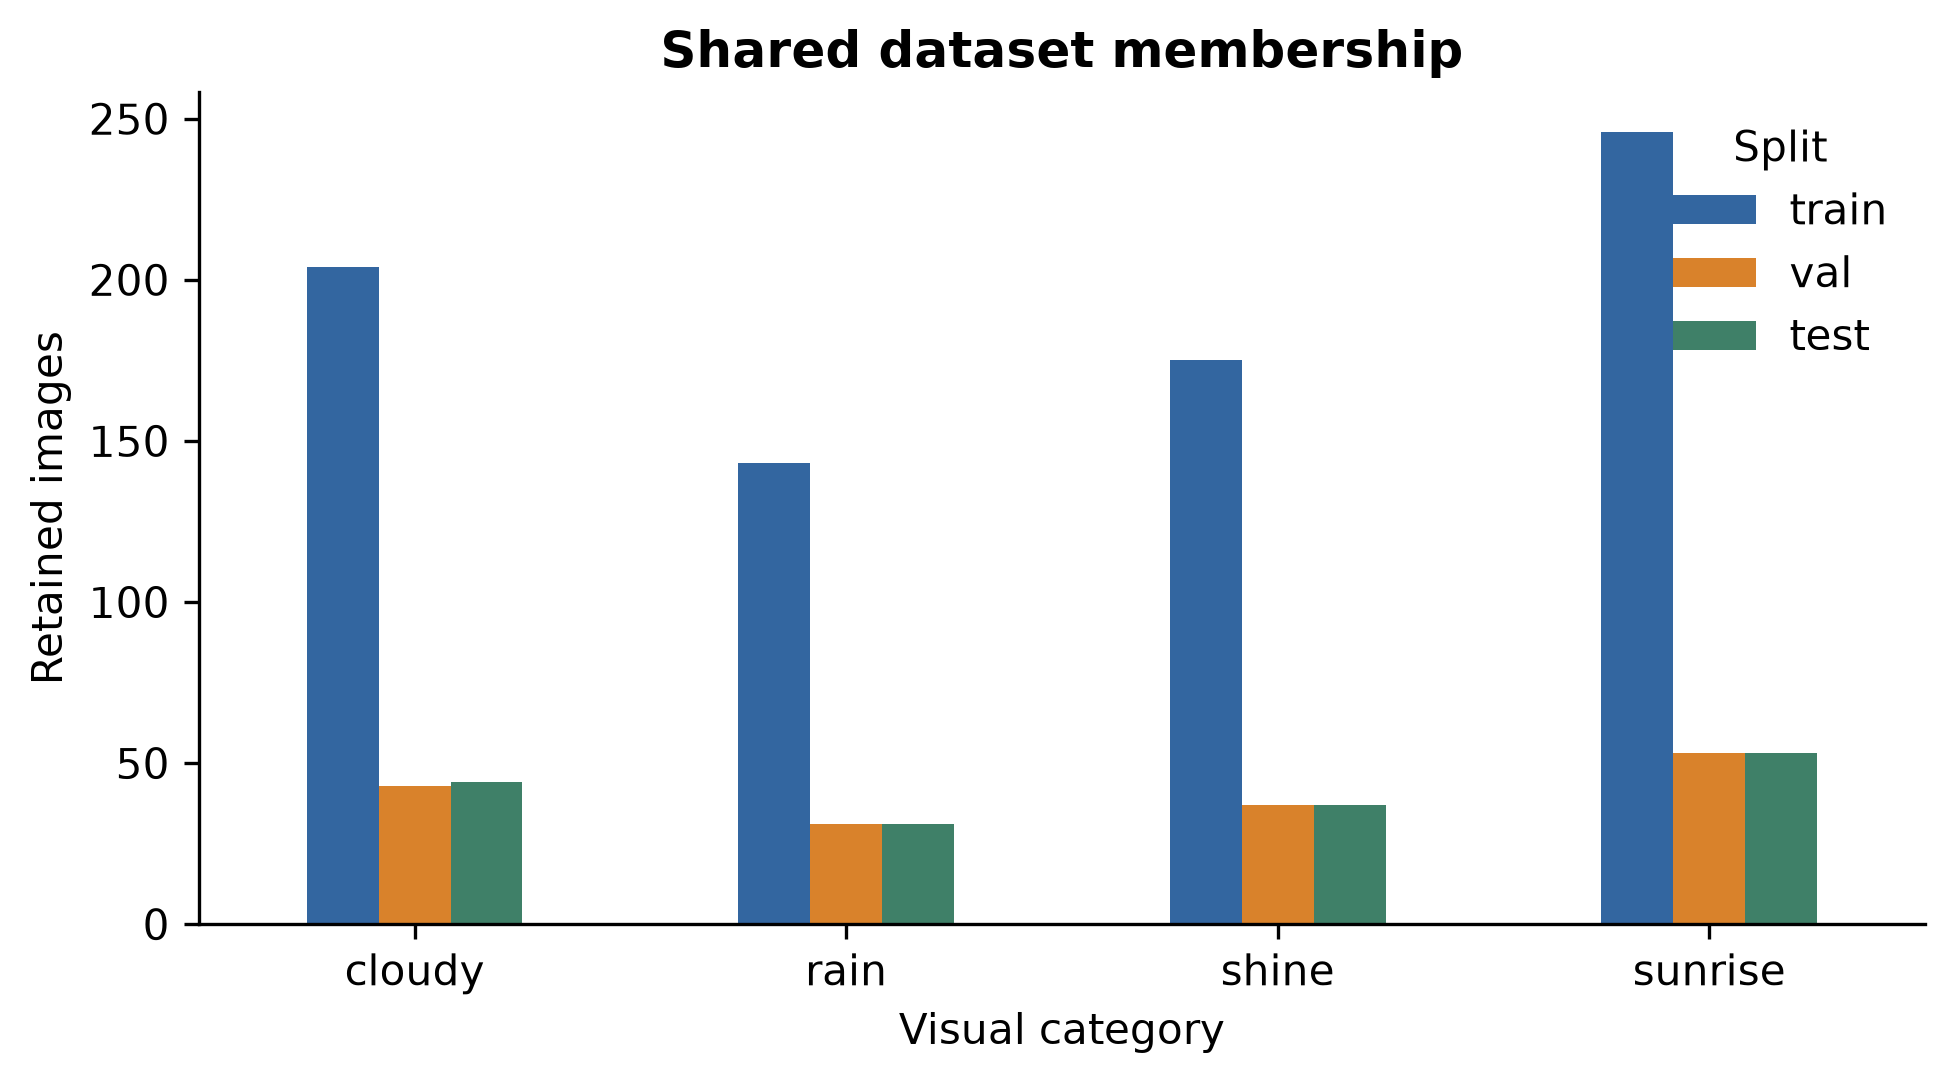

,path_a,path_b,label_a,label_b,kind,phash_distance,dhash_distance,rgb_rmse
0,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,near,0,0,0.004294
1,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,near,0,0,0.005025
2,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,near,0,2,0.005192
3,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,near,0,1,0.005055
4,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,exact,0,0,0.000000
5,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,near,0,1,0.007794
6,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,exact,0,0,0.000000
7,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,near,0,0,0.005950
8,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,near,2,0,0.007158
9,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,data/raw/Weather-Analysis-ad78ac8fcf1b1aae229c...,cloudy,cloudy,near,0,0,0.005950


Manifest and file-content checks passed.


In [4]:
from IPython.display import display, Image as IPImage
for name in ['inspection.png', 'class_distribution.png']:
    display(IPImage(filename=f'data/{name}', width=760))
display(pd.read_csv('data/duplicate_pairs.csv').head(10))
from src.data import validate_manifest, verify_content
verify_content(manifest)
print('Manifest and file-content checks passed.')

## 5. Configurations and model architectures

The Simple CNN uses three Conv-BatchNorm-ReLU-Pool blocks (16, 32, 64 channels), global average pooling, dropout, and a four-logit head. MobileNetV2 uses inverted residuals and depthwise convolution. ConvNeXt-Tiny is a modern CNN using large depthwise kernels and hierarchical features. Both transfer models start from ImageNet-1K V1 weights and train only the new linear head. Frozen feature extractors remain in evaluation mode, preserving BatchNorm and stochastic-depth behavior.

AdamW and cross-entropy are used. Validation macro-F1 selects the best checkpoint; patience controls early stopping. Test images do not enter training/model selection. For a fresh training run, work in a separate copy, move `outputs/` to `outputs_saved/`, and set `USE_RELEASED_CHECKPOINTS=False`. This preserves existing results while the training cells create new ones. Edit hyperparameters **before** training; existing runs with different settings are rejected. ConvNeXt ablation settings must differ only in `augment`. Full checkpoints avoid any pretrained download during inference.

In [5]:
import yaml
CONFIG = Path('configs/experiments.yaml')
settings = yaml.safe_load(CONFIG.read_text())
# Optional: edit settings['experiments'][...], then CONFIG.write_text(yaml.safe_dump(settings, sort_keys=False)).
# Always keep all ConvNeXt settings equal except augment. Default seed is 42.
print(CONFIG.read_text())
# Download the released checkpoints for a demonstration; omit this for fresh training.
USE_RELEASED_CHECKPOINTS = True
if USE_RELEASED_CHECKPOINTS:
    subprocess.run([sys.executable, 'scripts/download_checkpoints.py', '--all'], check=True)
from src.config import load_config, validate_ablation
configs = load_config(CONFIG)
validate_ablation(configs['convnext_aug'], configs['convnext_noaug'])
RESUME = True

def train_run(name):
    args = ['train', '--config', CONFIG, '--run', name, '--skip-complete']
    if RESUME and Path(f'outputs/{name}/status.json').exists():
        args.append('--resume')
    cli(*args)

seed: 42
image_size: 224
num_workers: 0
device: auto
experiments:
  cnn_baseline:
    model: cnn
    epochs: 12
    batch_size: 32
    lr: 0.001
    weight_decay: 0.0001
    patience: 4
    augment: true
    pretrained: false
    freeze_backbone: false
  mobilenet_improved:
    model: mobilenet
    epochs: 8
    batch_size: 32
    lr: 0.001
    weight_decay: 0.0001
    patience: 4
    augment: true
    pretrained: true
    freeze_backbone: true
  convnext_aug:
    model: convnext
    epochs: 6
    batch_size: 16
    lr: 0.001
    weight_decay: 0.0001
    patience: 4
    augment: true
    pretrained: true
    freeze_backbone: true
  convnext_noaug:
    model: convnext
    epochs: 6
    batch_size: 16
    lr: 0.001
    weight_decay: 0.0001
    patience: 4
    augment: false
    pretrained: true
    freeze_backbone: true

cnn_baseline: verified existing
convnext_aug: verified existing


convnext_noaug: verified existing
mobilenet_improved: verified existing


## 6. Automated tests and optional isolated smoke test

Tests are offline and use temporary synthetic fixtures. The smoke test uses four real images per class per split and one epoch. Its outputs remain in `outputs/smoke`; these are not full experiment results.

In [6]:
subprocess.run([sys.executable, '-m', 'pytest', '-q'], check=True)
RUN_SMOKE = False
if RUN_SMOKE:
    subprocess.run([sys.executable, 'scripts/smoke.py'], check=True)

.

......

.....

.

.

.

... (4 outputs left out)

...

.

.

.                                 [100%]
40 passed in 18.25s


## 7. A1 baseline: train Simple CNN from scratch

In [7]:
train_run('cnn_baseline')

2026-11-03 11:37:02,638 INFO Skipping completed run cnn_baseline


## 8. A1 improved model: train MobileNetV2 classification head

In [8]:
train_run('mobilenet_improved')

2026-11-03 11:37:04,515 INFO Skipping completed run mobilenet_improved


## 9. A2 advanced model: train ConvNeXt-Tiny with augmentation

In [9]:
train_run('convnext_aug')

2026-11-03 11:37:06,403 INFO Skipping completed run convnext_aug


## 10. Controlled ablation: ConvNeXt-Tiny without augmentation

Same architecture, initialization protocol, pretrained weights, manifest, shuffle seeds, optimizer, learning rate, batch size, epoch limit, and early stopping; only augmentation changes. Each run independently selects its best epoch by validation macro-F1. Do not tune configurations based on the forthcoming test results.

In [10]:
train_run('convnext_noaug')

2026-11-03 11:37:08,318 INFO Skipping completed run convnext_noaug


## 11. Final held-out test evaluation and comparison

Run after all configurations are finalized. Accuracy, macro precision/recall/F1, per-class scores, predictions, and confusion matrices are generated from actual test images. Batch-one latency uses 5 warm-up runs and 30 synchronized repeated forwards of the same resident test tensor. Preprocessing, transfer, I/O, model loading, and softmax are excluded from the benchmark. Hardware and raw timings are saved. Measurements on T4 and local CPU/MPS are not interchangeable.

In [11]:
REEVALUATE = False  # True deliberately replaces test outputs and latency for this machine.
if REEVALUATE or any(not Path(f'outputs/{run}/test_metrics.json').exists() for run in configs):
    cli('evaluate', '--runs', *configs)
else:
    from src.engine import calculate_metrics
    import numpy as np
    for run in configs:
        saved = json.loads(Path(f'outputs/{run}/test_metrics.json').read_text())
        pred = pd.read_csv(f'outputs/{run}/test_predictions.csv')
        actual = calculate_metrics(pred.class_id.tolist(), pred.predicted_class_id.tolist())
        for metric in ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'confusion_matrix']:
            assert np.allclose(saved[metric], actual[metric])
    print('Recalculated all four saved test results from predictions; existing timing environment retained.')
    from src.evaluation import compare_runs
    compare_runs(list(configs), Path('outputs'))
comparison = pd.read_csv('outputs/model_comparison.csv')
display(comparison)
display(pd.read_csv('outputs/ablation.csv'))
print(Path('outputs/ablation_analysis.json').read_text())

Recalculated all four saved test results from predictions; existing timing environment retained.


,run,model,augment,accuracy,precision_macro,recall_macro,f1_macro,test_samples,latency_mean_ms,latency_median_ms,parameters,trainable_parameters,training_seconds,best_epoch,validation_f1_macro,device
0,cnn_baseline,cnn,True,0.951515,0.948891,0.947287,0.947713,165,0.729060,0.742208,23956,23956,30.614942,9,0.854397,mps
1,mobilenet_improved,mobilenet,True,0.963636,0.962430,0.962451,0.962003,165,12.171304,10.269354,2228996,5124,22.399437,8,0.939049,mps
2,convnext_aug,convnext,True,0.981818,0.986607,0.979497,0.982723,165,6.715647,6.493667,27823204,3076,38.999347,3,0.957896,mps
3,convnext_noaug,convnext,False,0.975758,0.979798,0.972740,0.975901,165,6.310290,6.273083,27823204,3076,38.134550,5,0.956991,mps


,run,model,augment,accuracy,precision_macro,recall_macro,f1_macro,test_samples,latency_mean_ms,latency_median_ms,parameters,trainable_parameters,training_seconds,best_epoch,validation_f1_macro,device
0,convnext_aug,convnext,True,0.981818,0.986607,0.979497,0.982723,165,6.715647,6.493667,27823204,3076,38.999347,3,0.957896,mps
1,convnext_noaug,convnext,False,0.975758,0.979798,0.972740,0.975901,165,6.310290,6.273083,27823204,3076,38.134550,5,0.956991,mps


{
  "comparison": "augmentation minus no augmentation",
  "test_f1_macro_delta": 0.006822085668617417,
  "interpretation": "Augmentation increased test macro-F1 by 0.0068 under the shared evaluation protocol.",
  "control": "All serialized configuration fields except augment are identical; identical manifest and test membership verified",
  "selection": "Each configuration selected its own best validation macro-F1 checkpoint; no test-based tuning"
}



## 12. Learning curves and confusion matrices

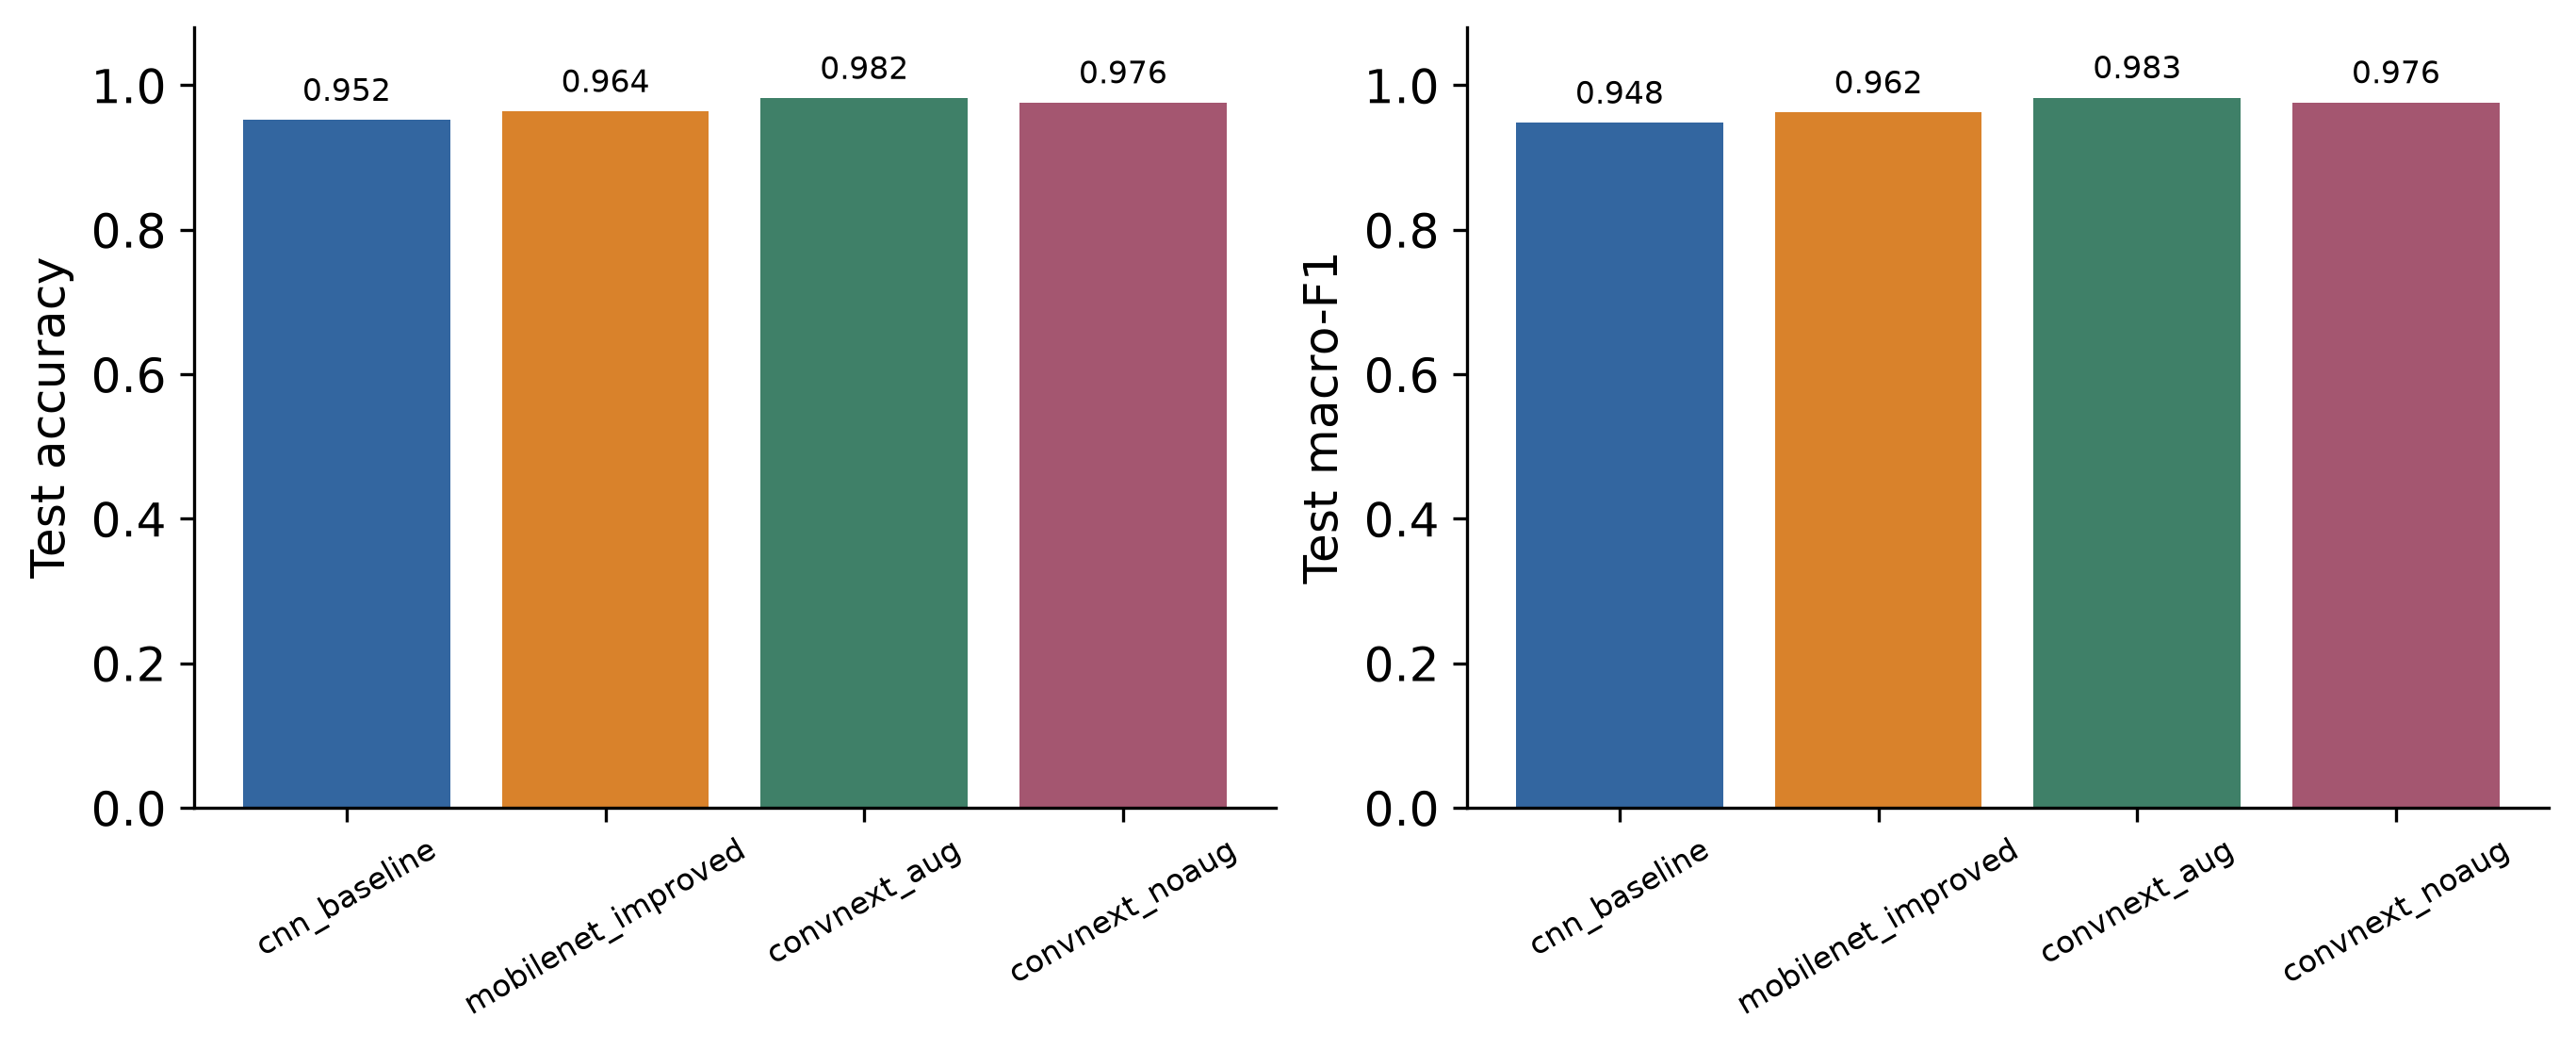

cnn_baseline


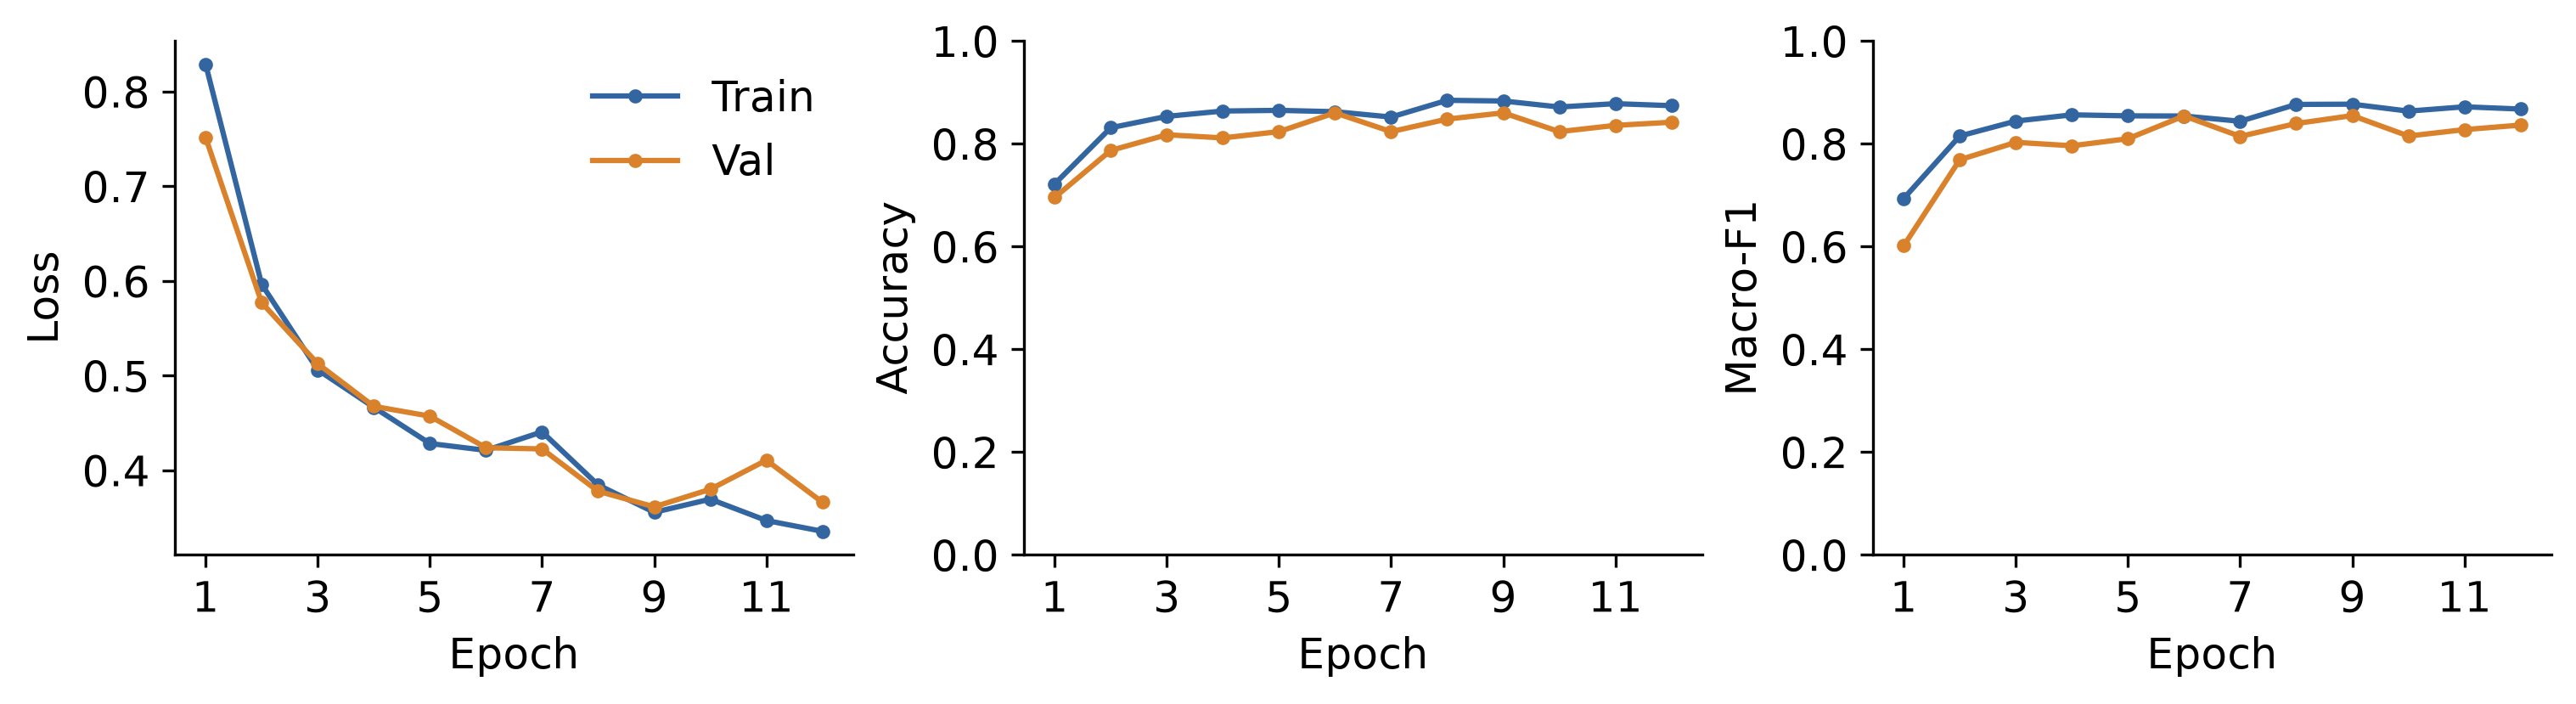

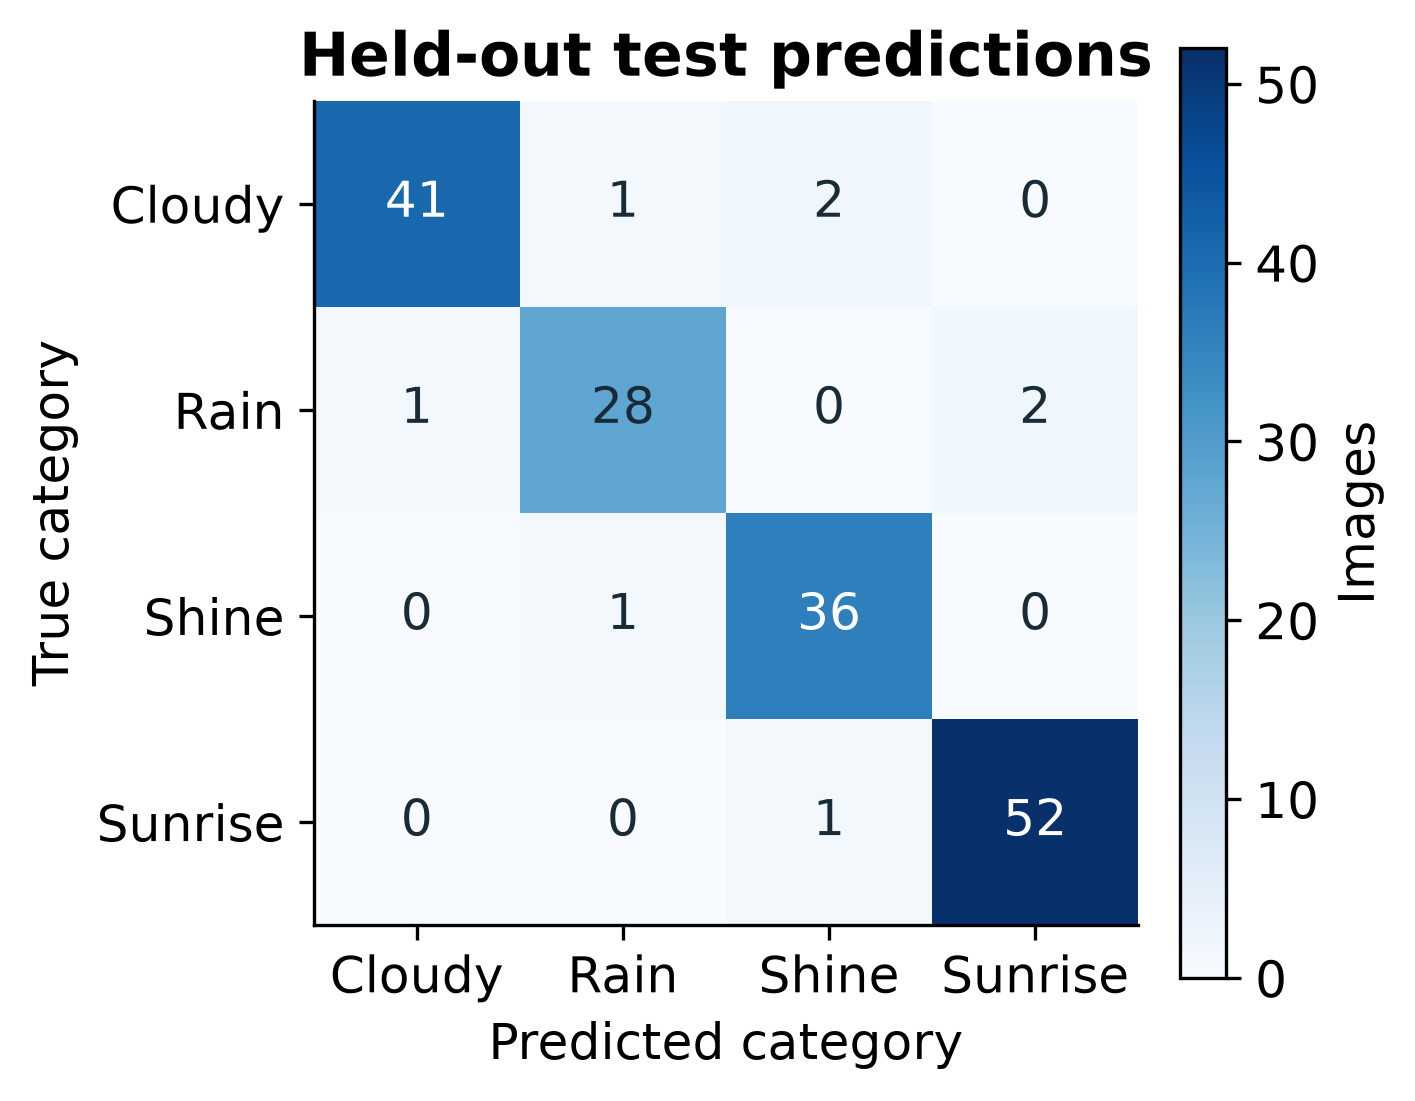

mobilenet_improved


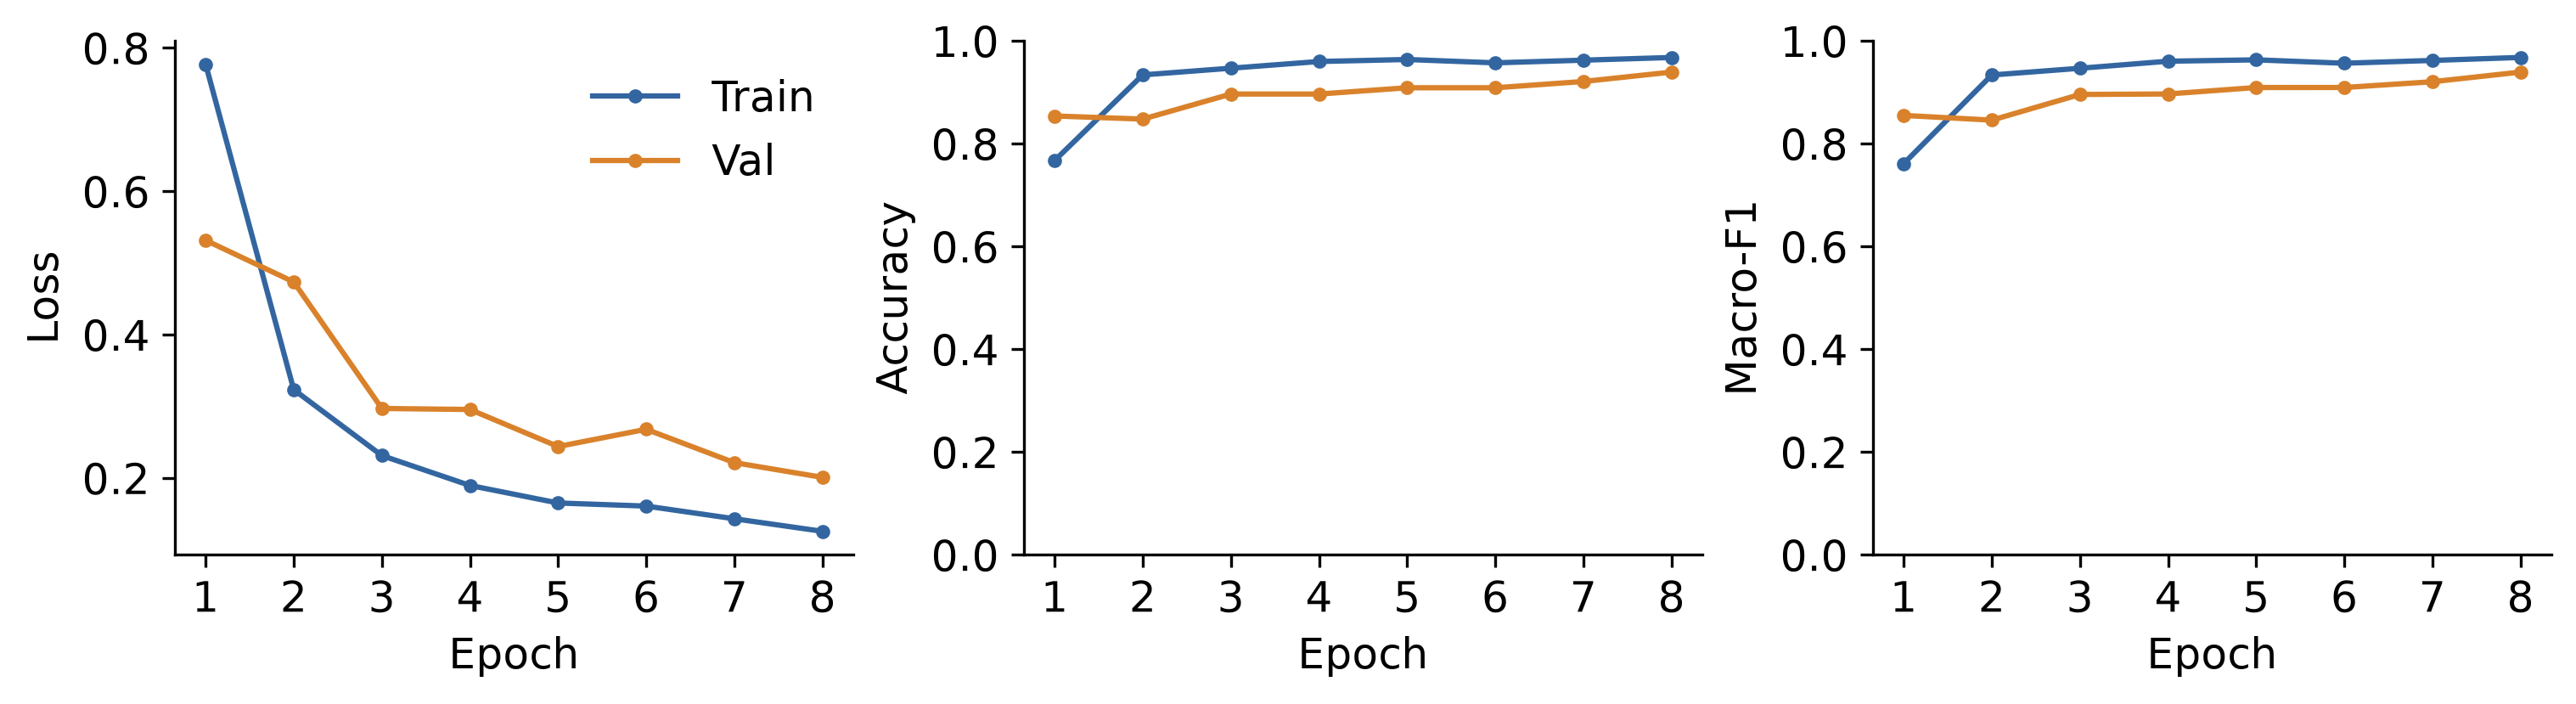

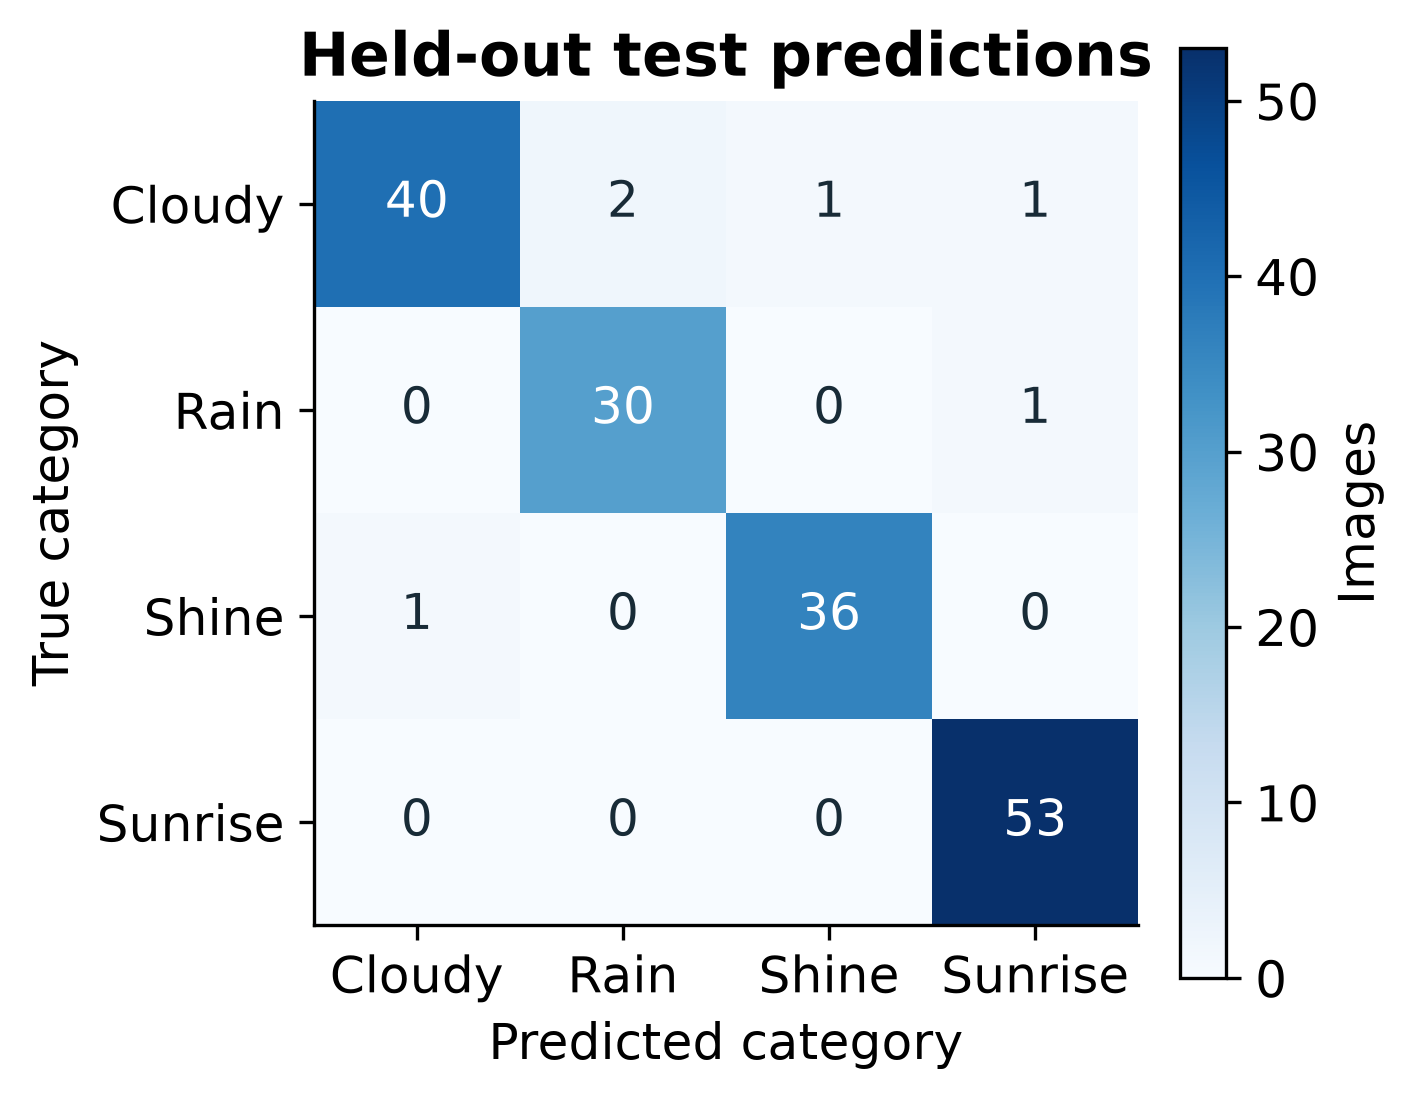

convnext_aug


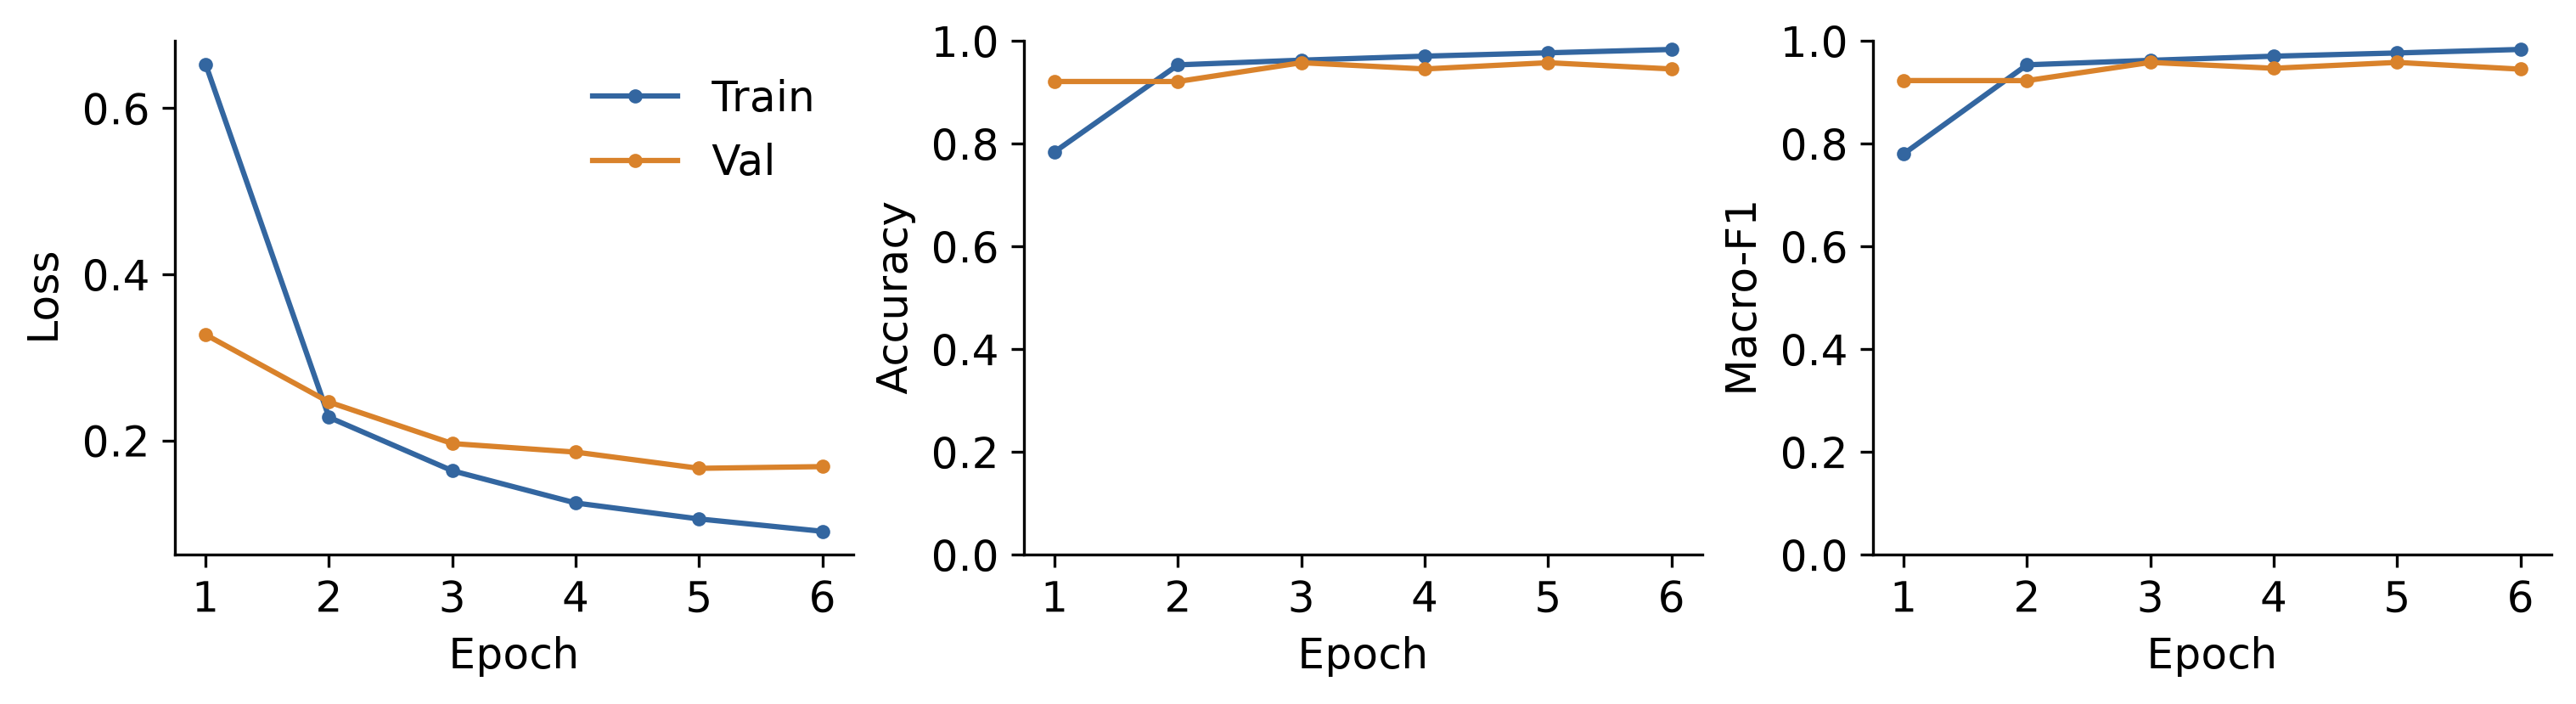

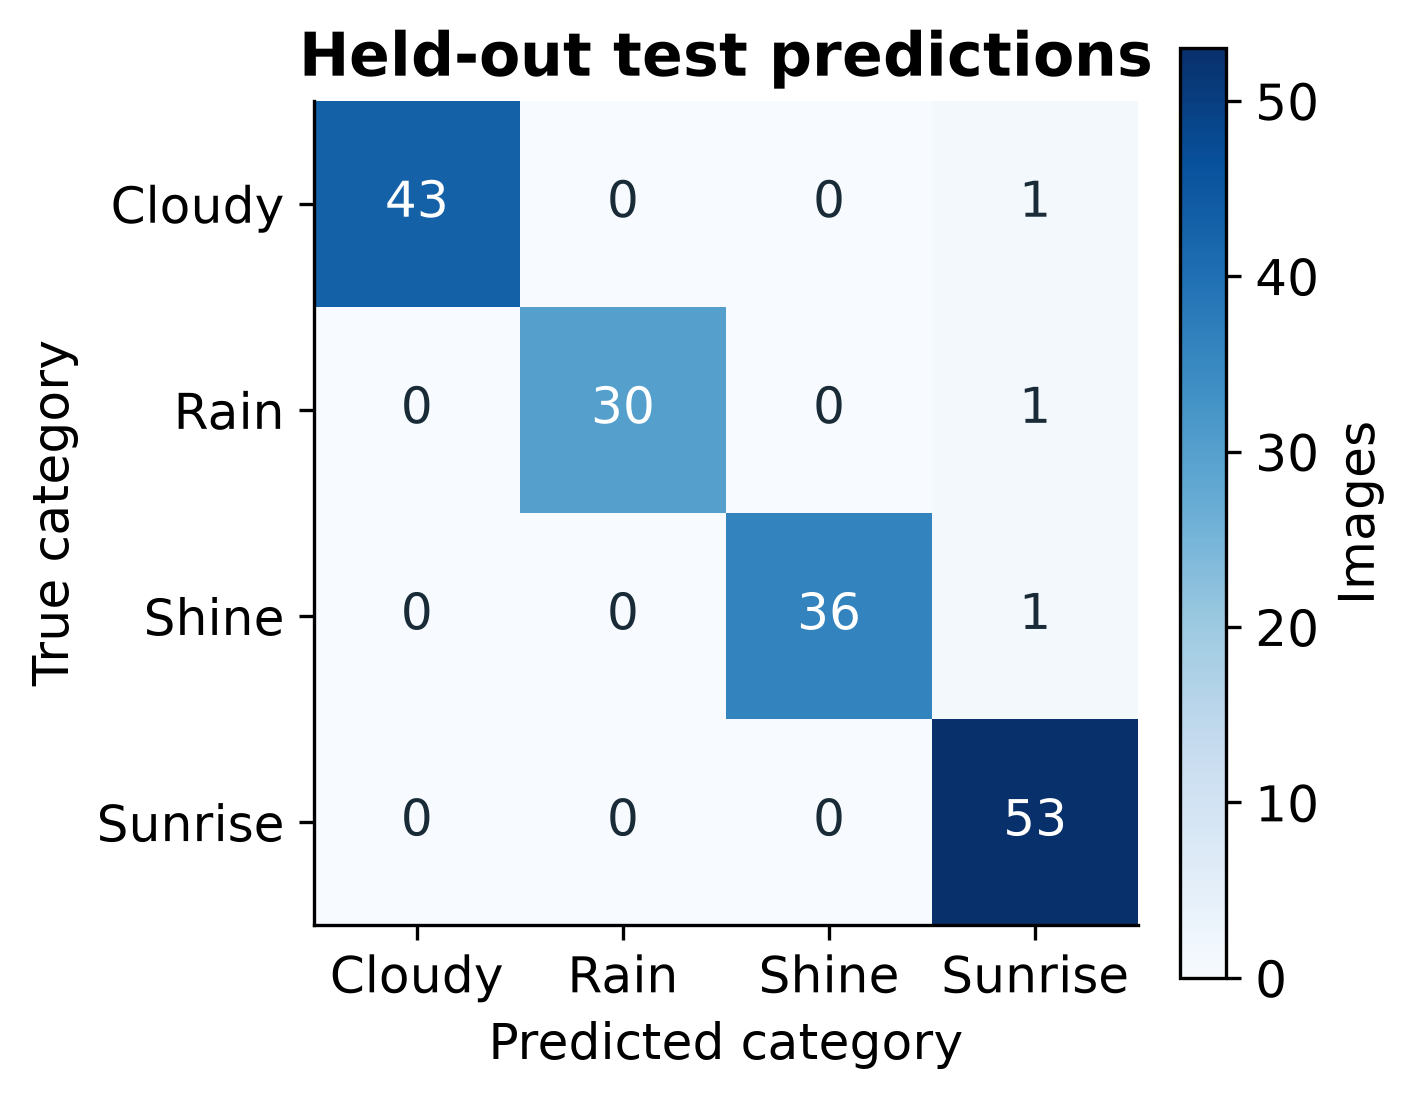

convnext_noaug


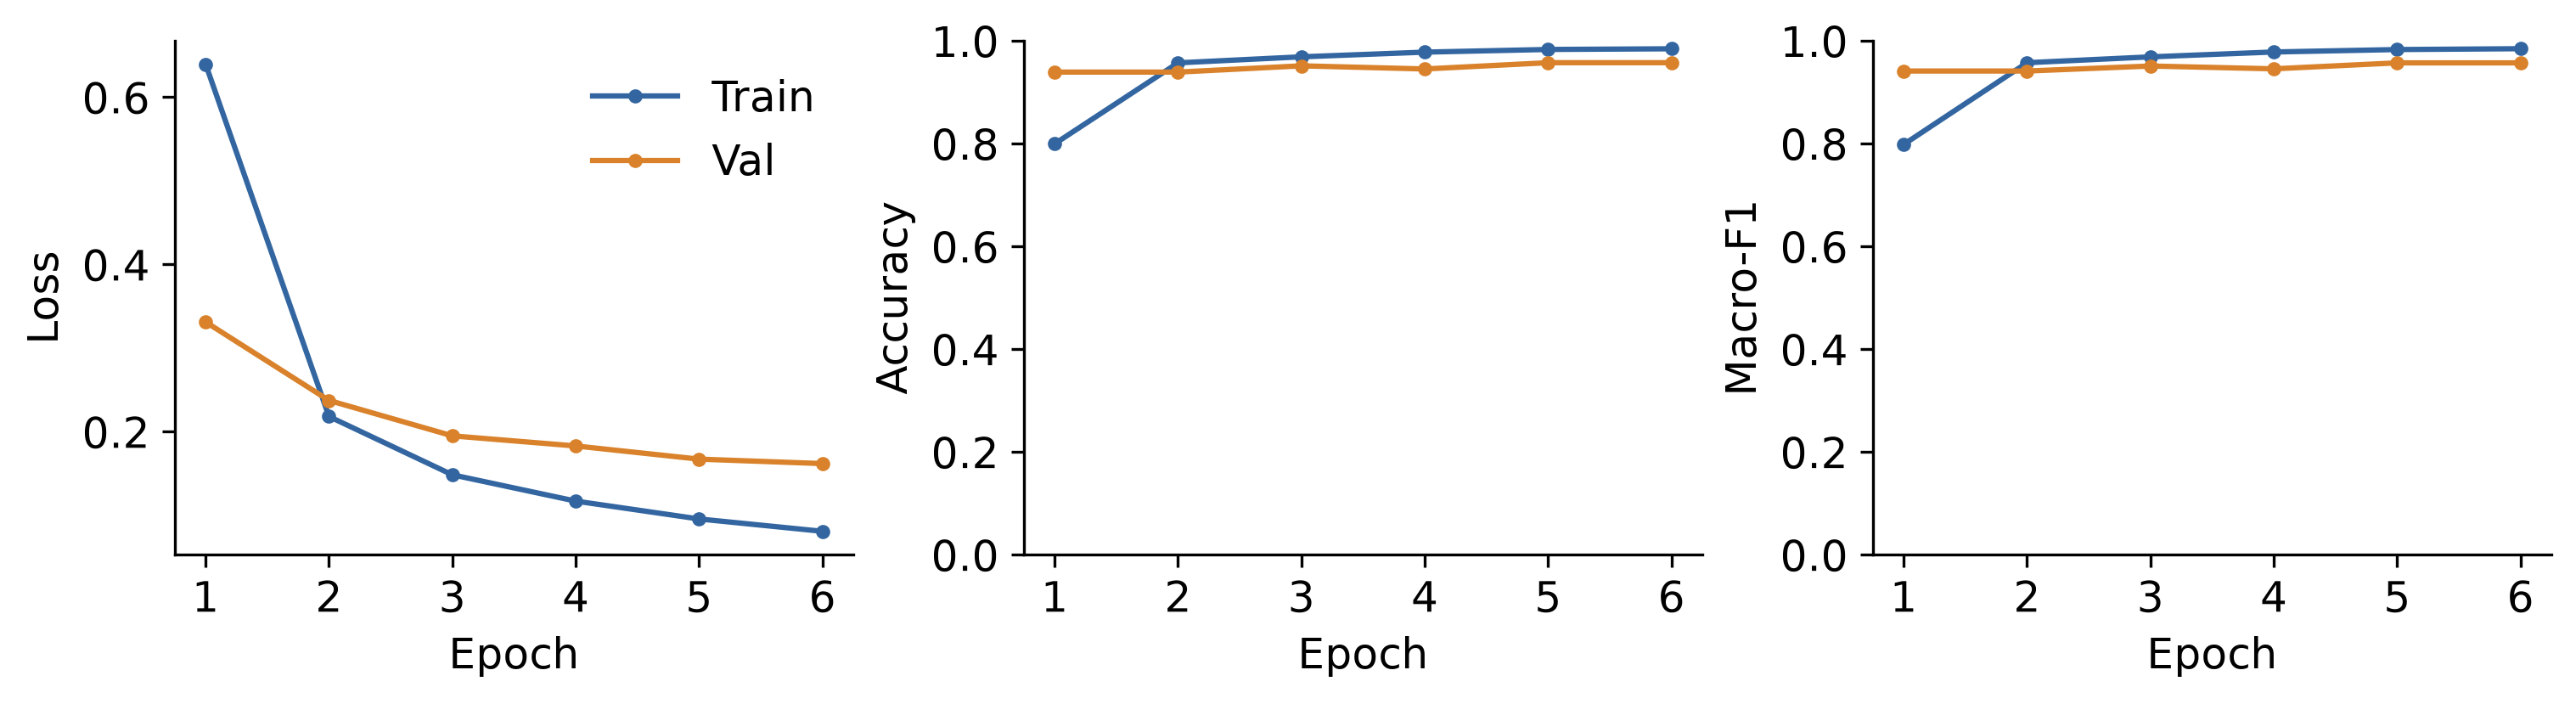

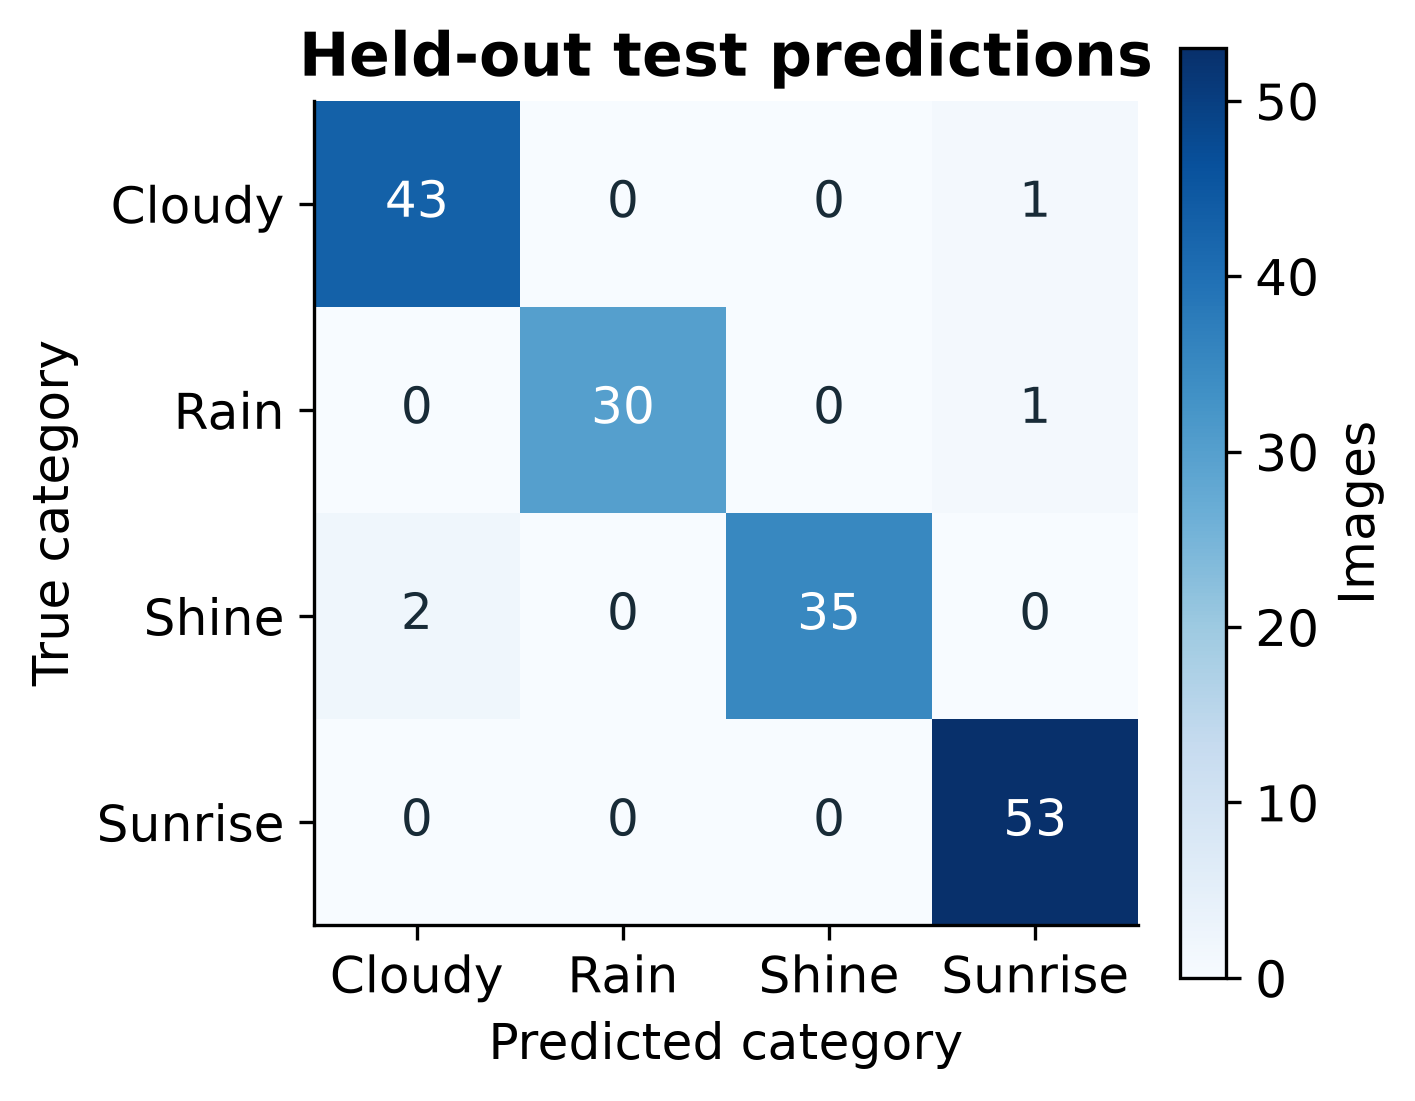

In [12]:
cli('figures')
subprocess.run([sys.executable, 'scripts/final_figures.py'], check=True)
display(IPImage(filename='outputs/model_comparison.png', width=850))
for run in configs:
    print(run)
    display(IPImage(filename=f'outputs/{run}/training_curves.png', width=900))
    display(IPImage(filename=f'outputs/{run}/confusion_matrix.png', width=420))

## 13. Grad-CAM on real, correctly and incorrectly classified test examples

Gradients of a selected class logit weight the final spatial feature maps at `features[-1]`. Frozen models still require an input graph. ReLU and normalization form the heatmap. The overlay inverts the resize/center-crop geometry onto the original photograph and preserves unseen borders. The heatmap gives an approximate spatial attribution for the selected class score. Errors are selected when available, after evaluation.

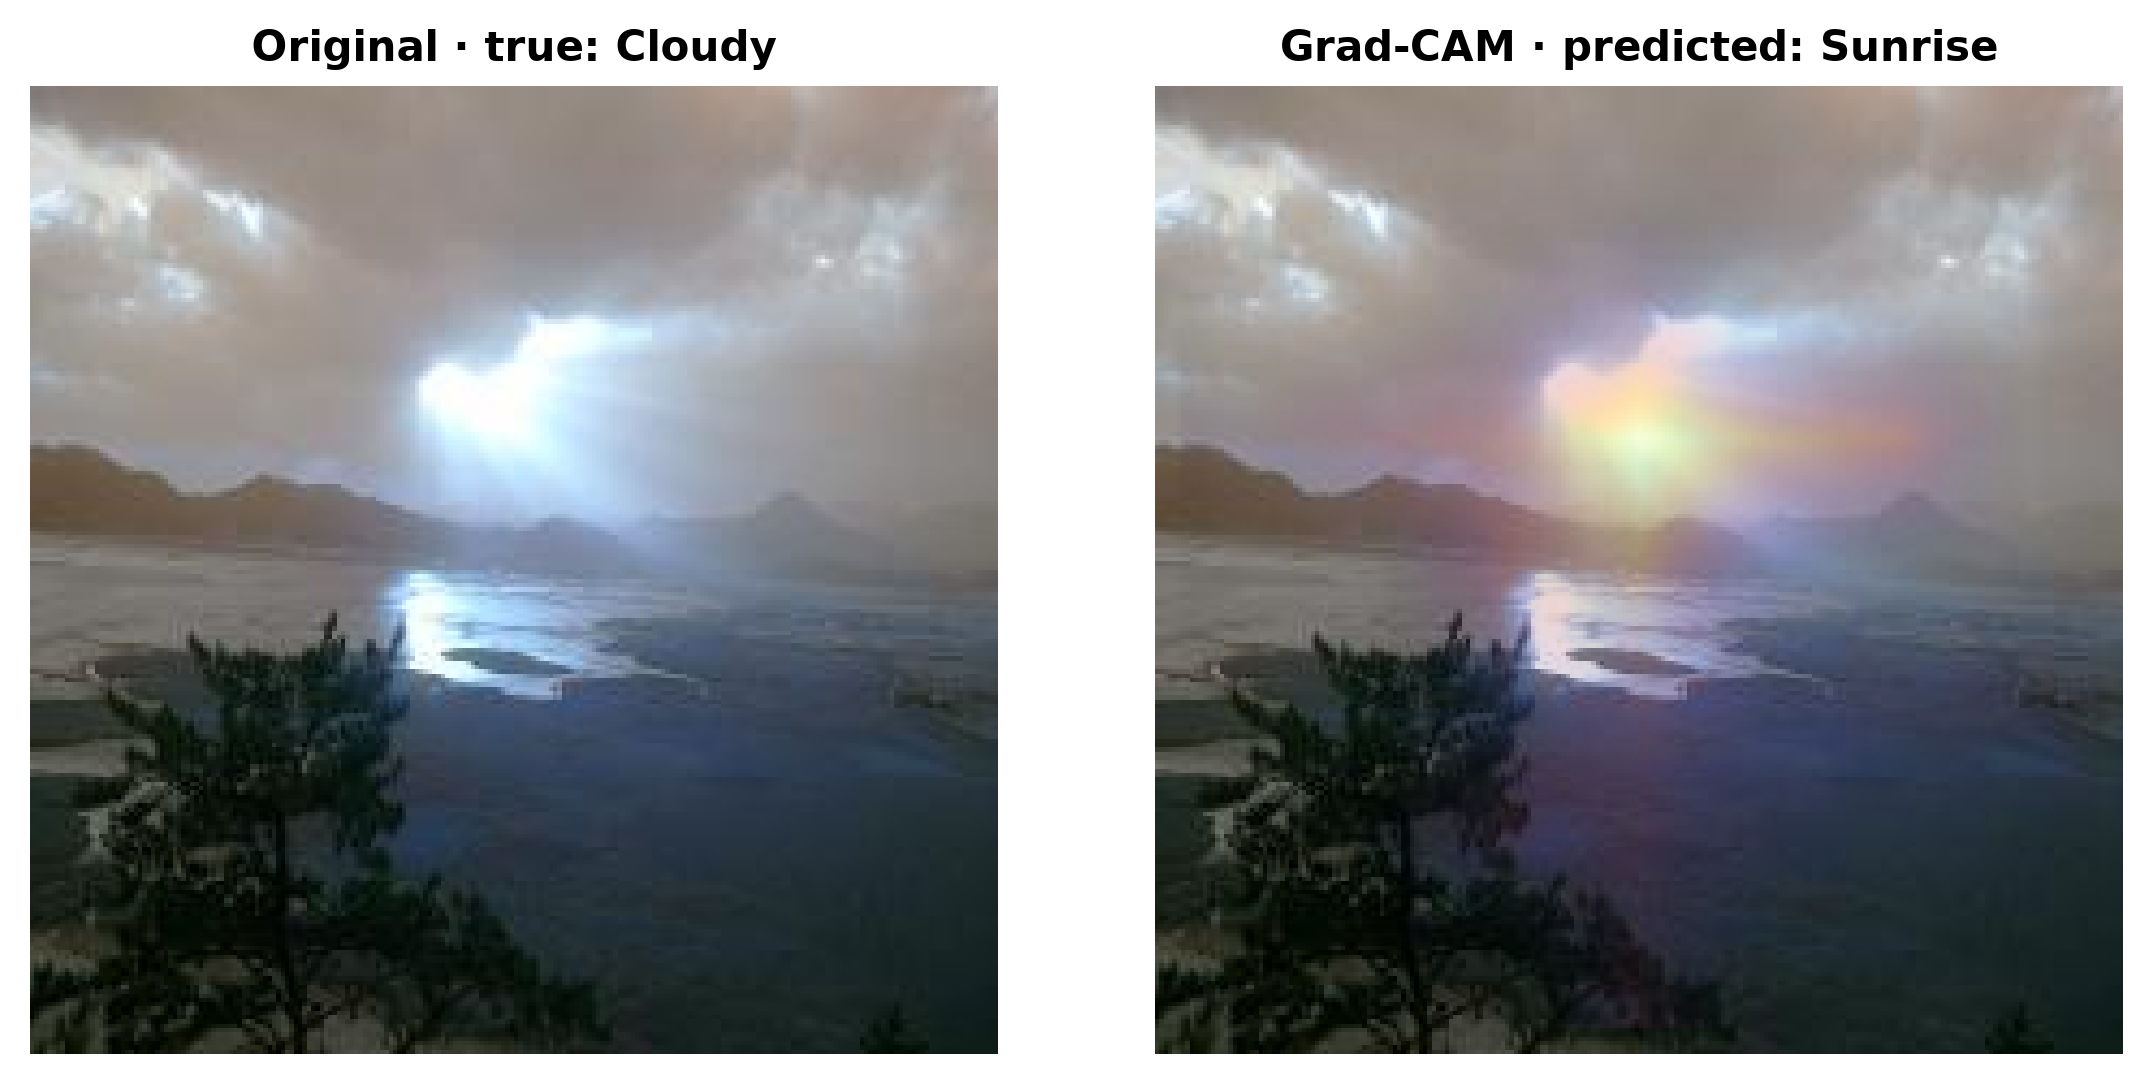

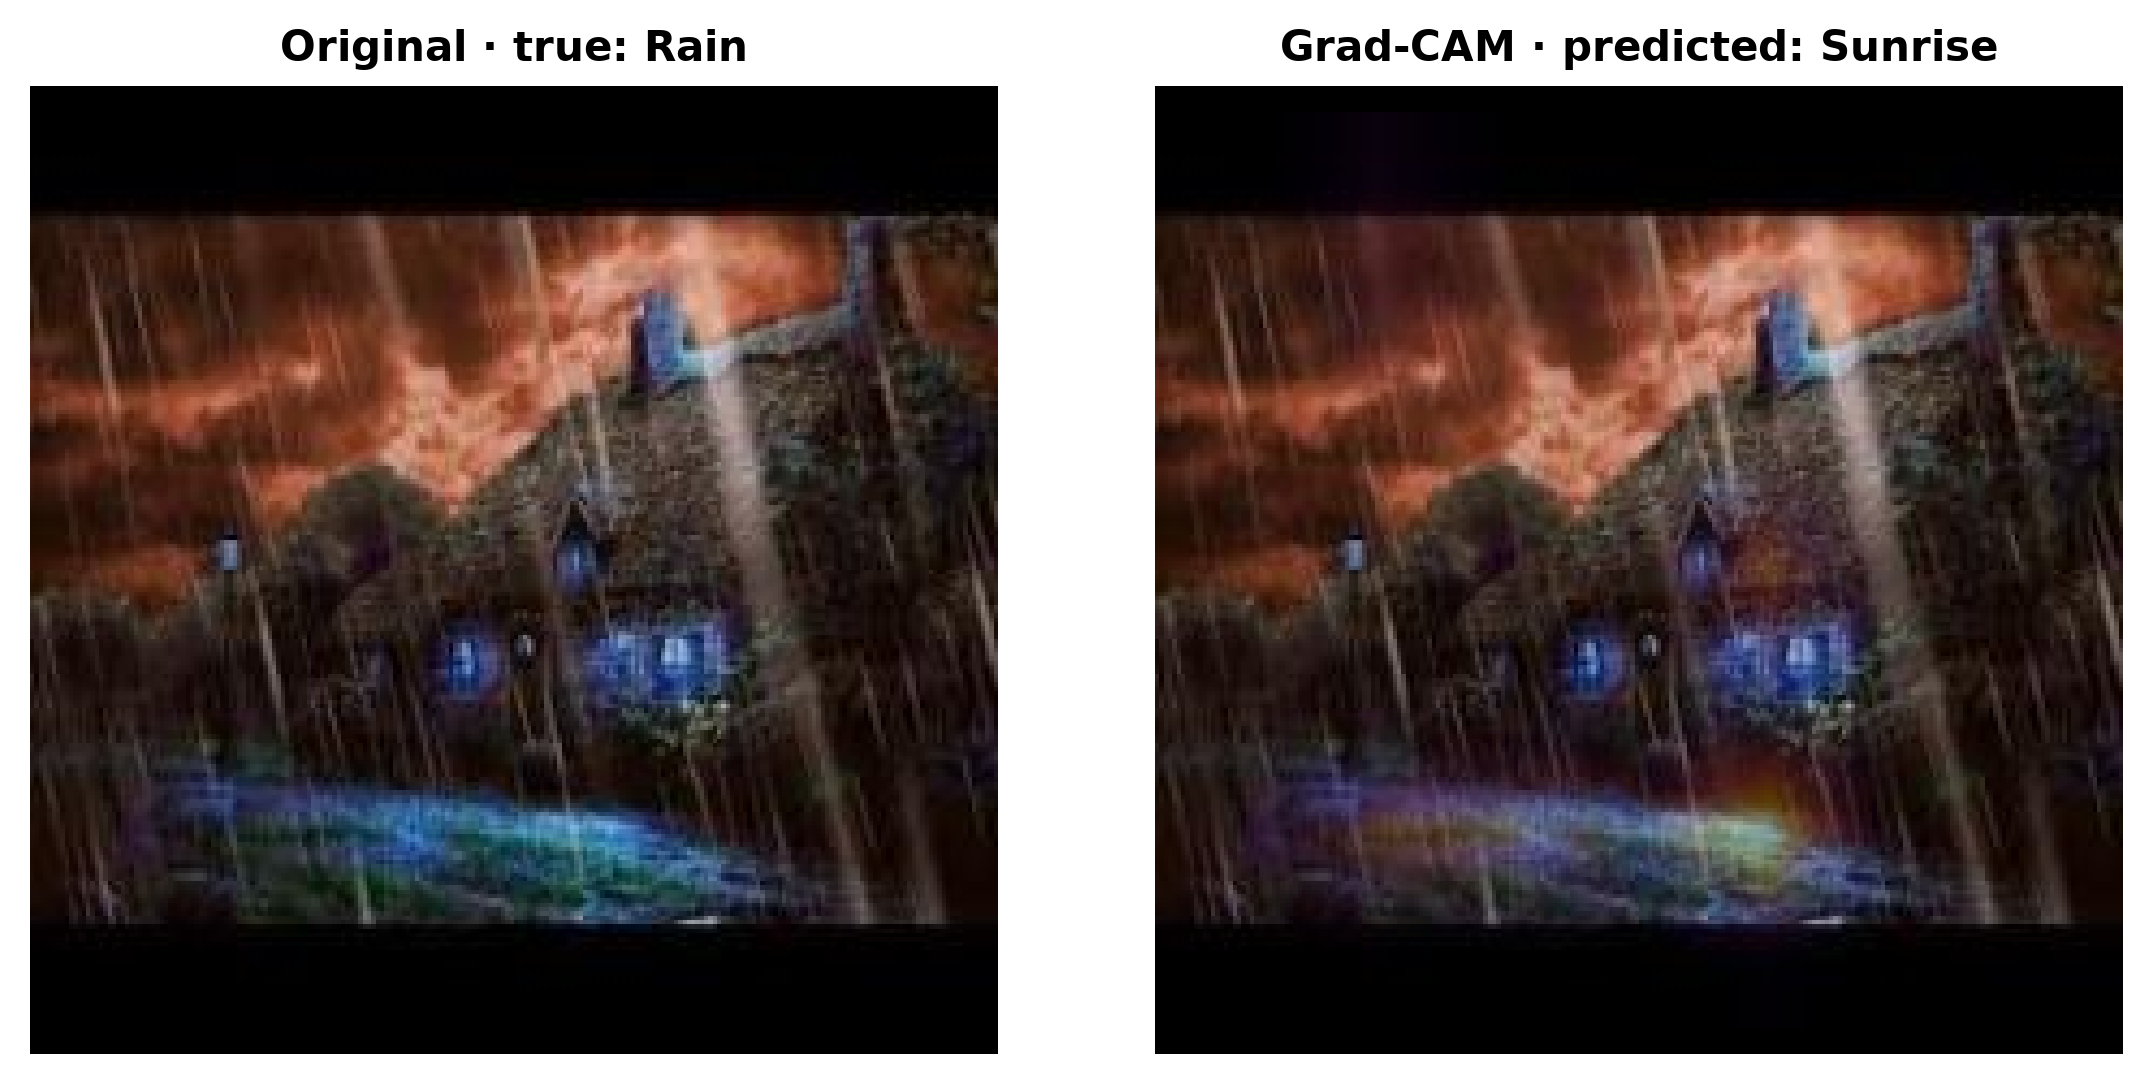

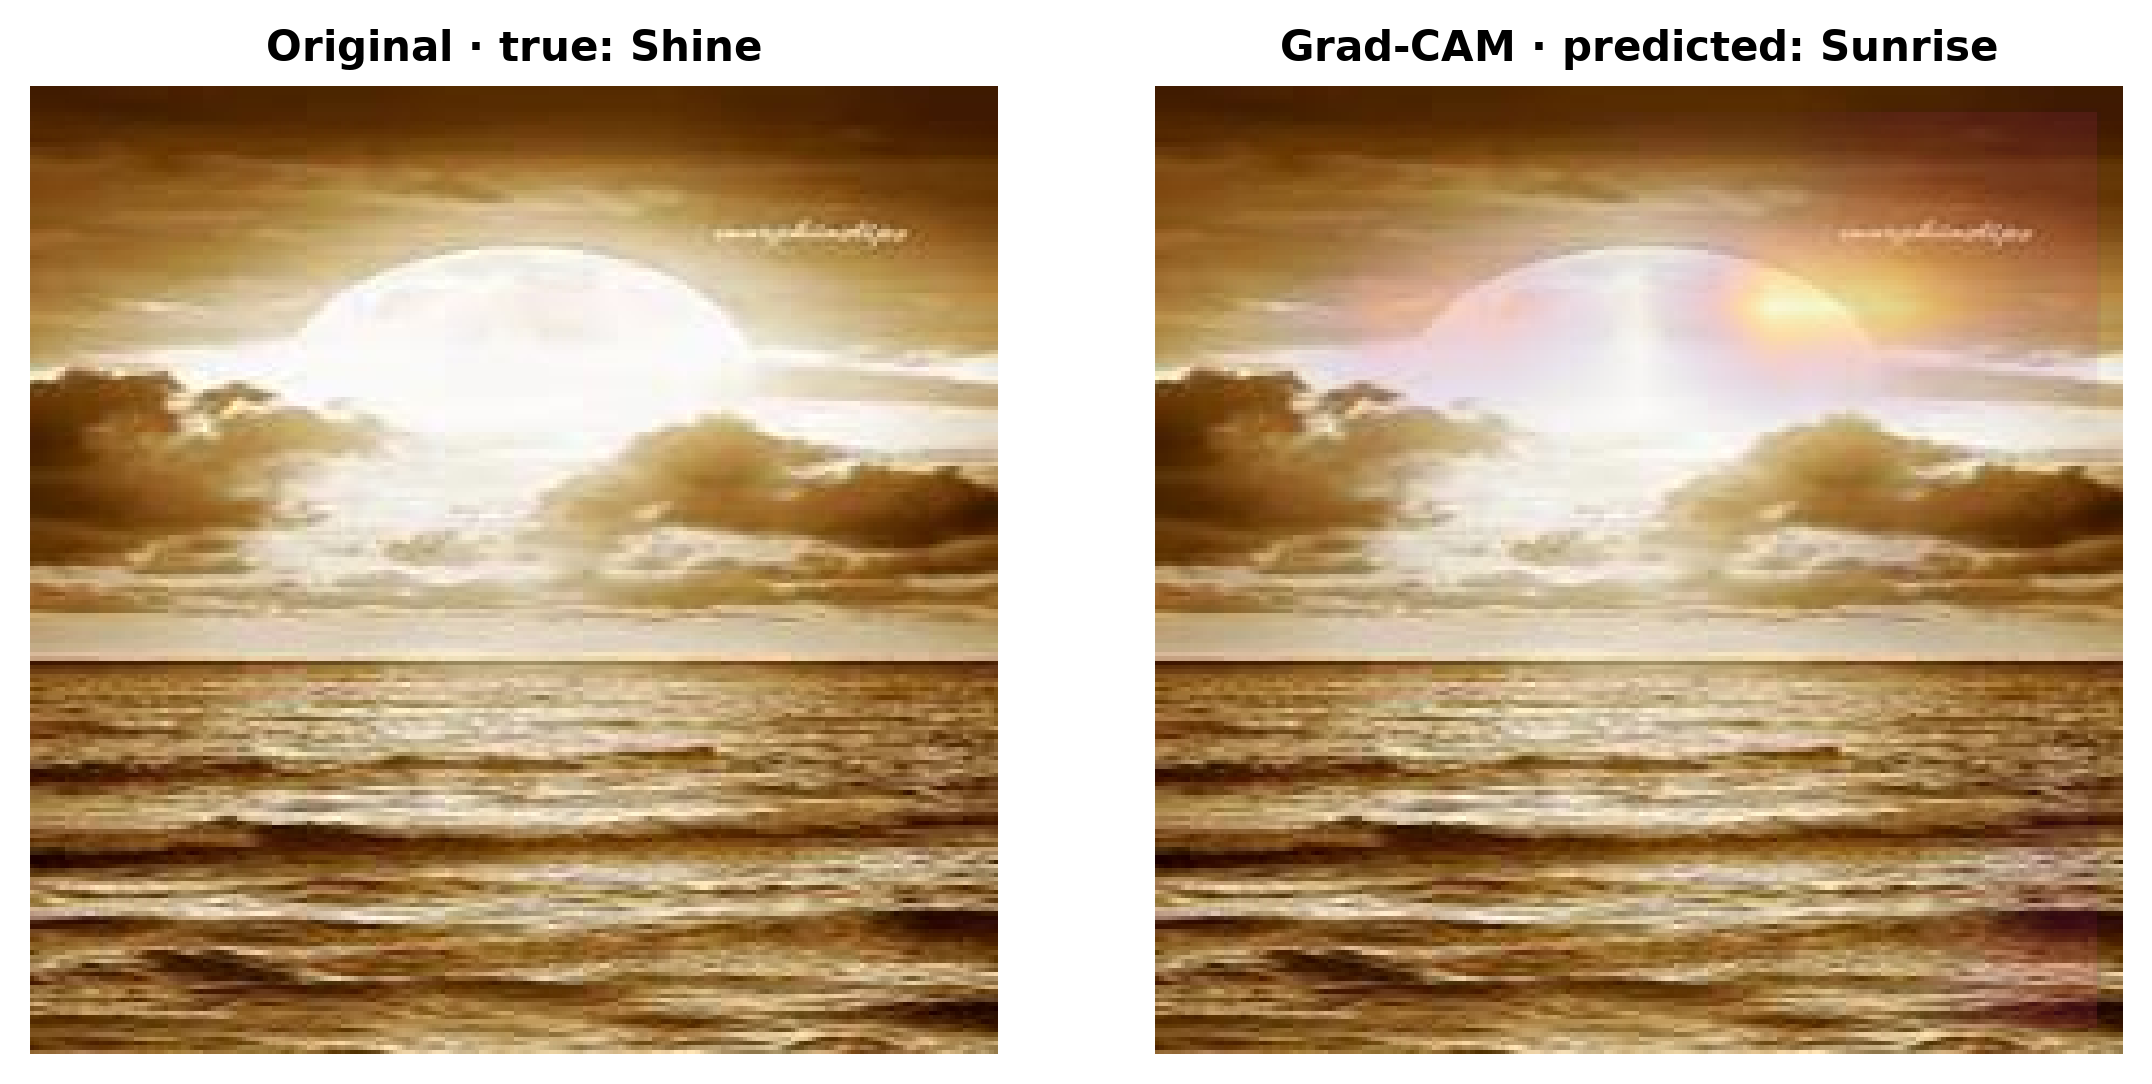

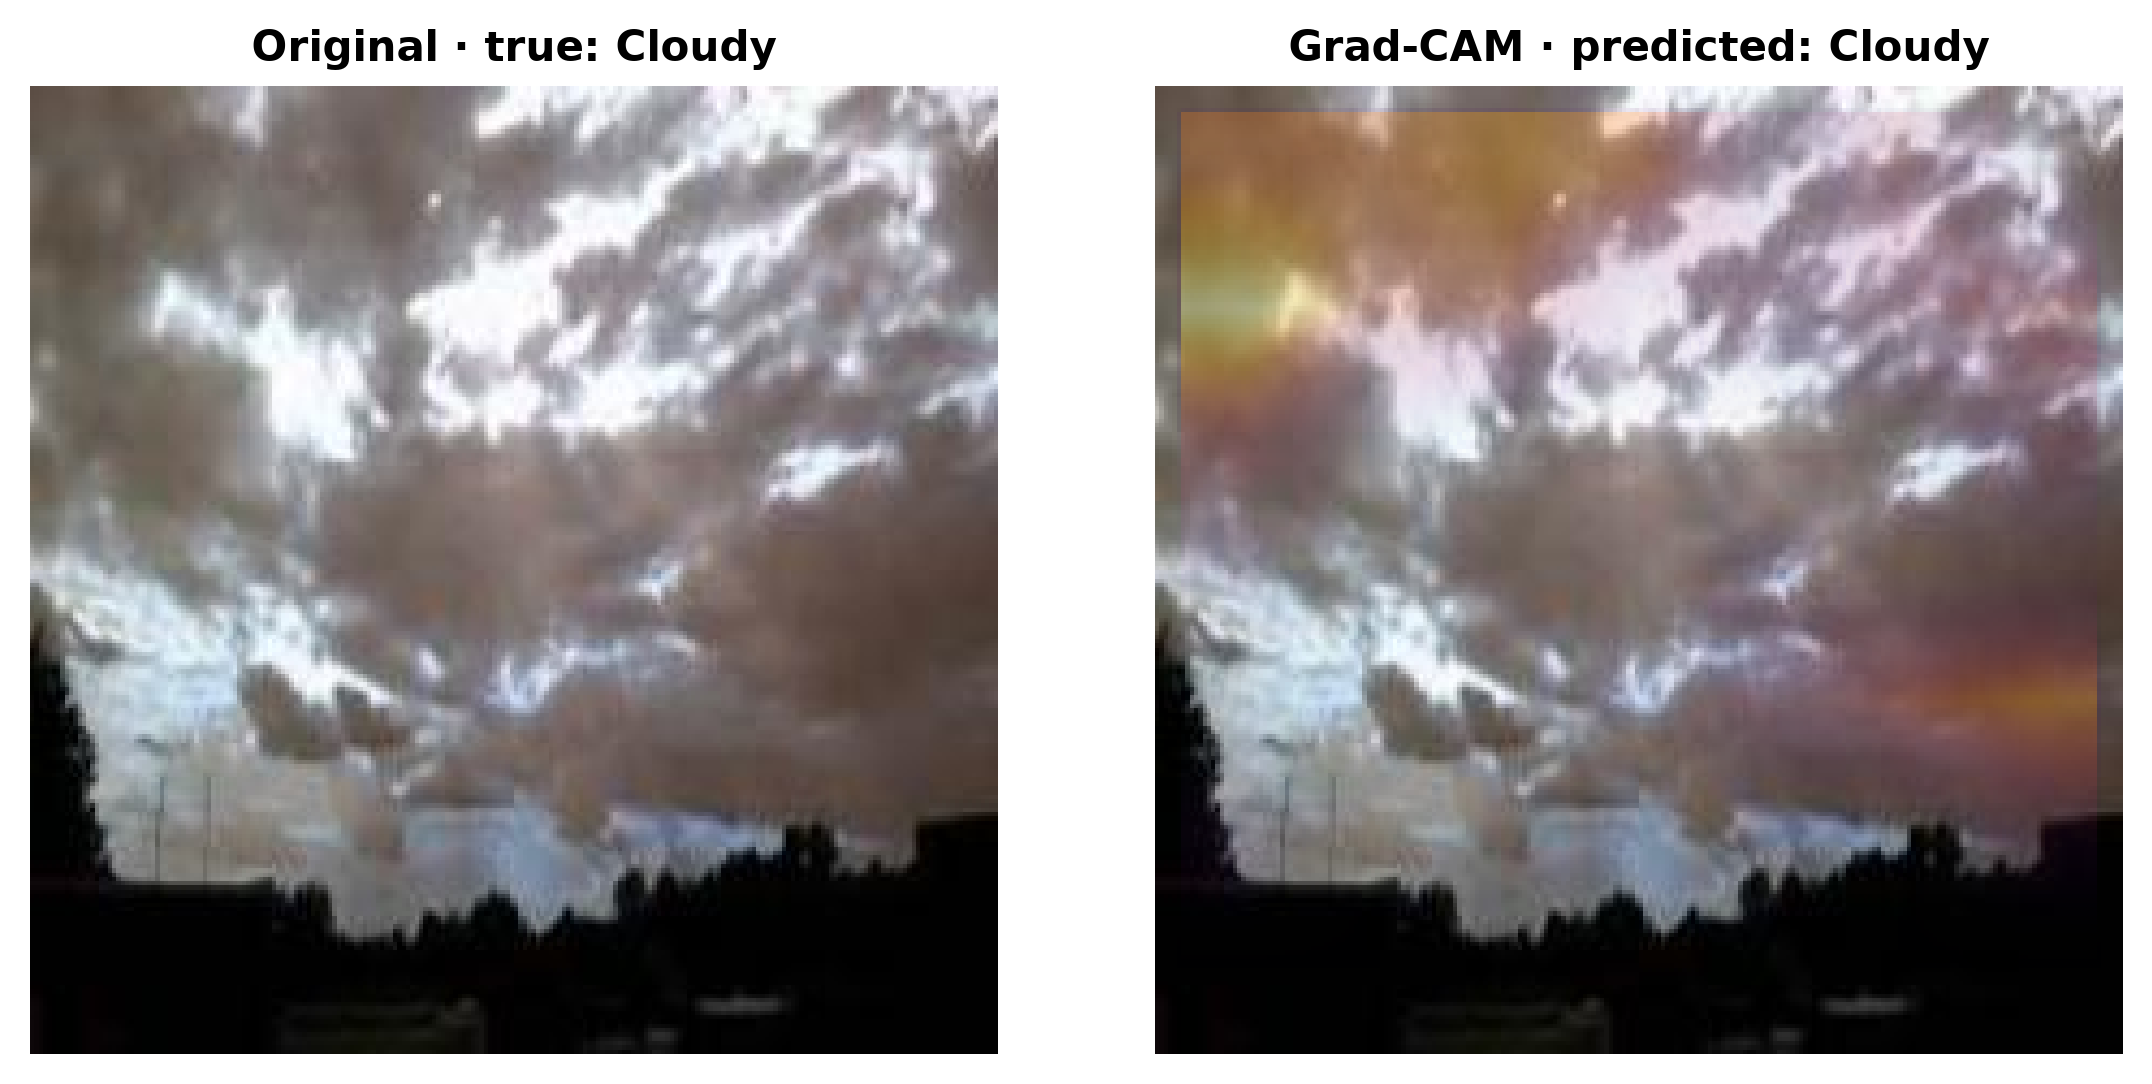

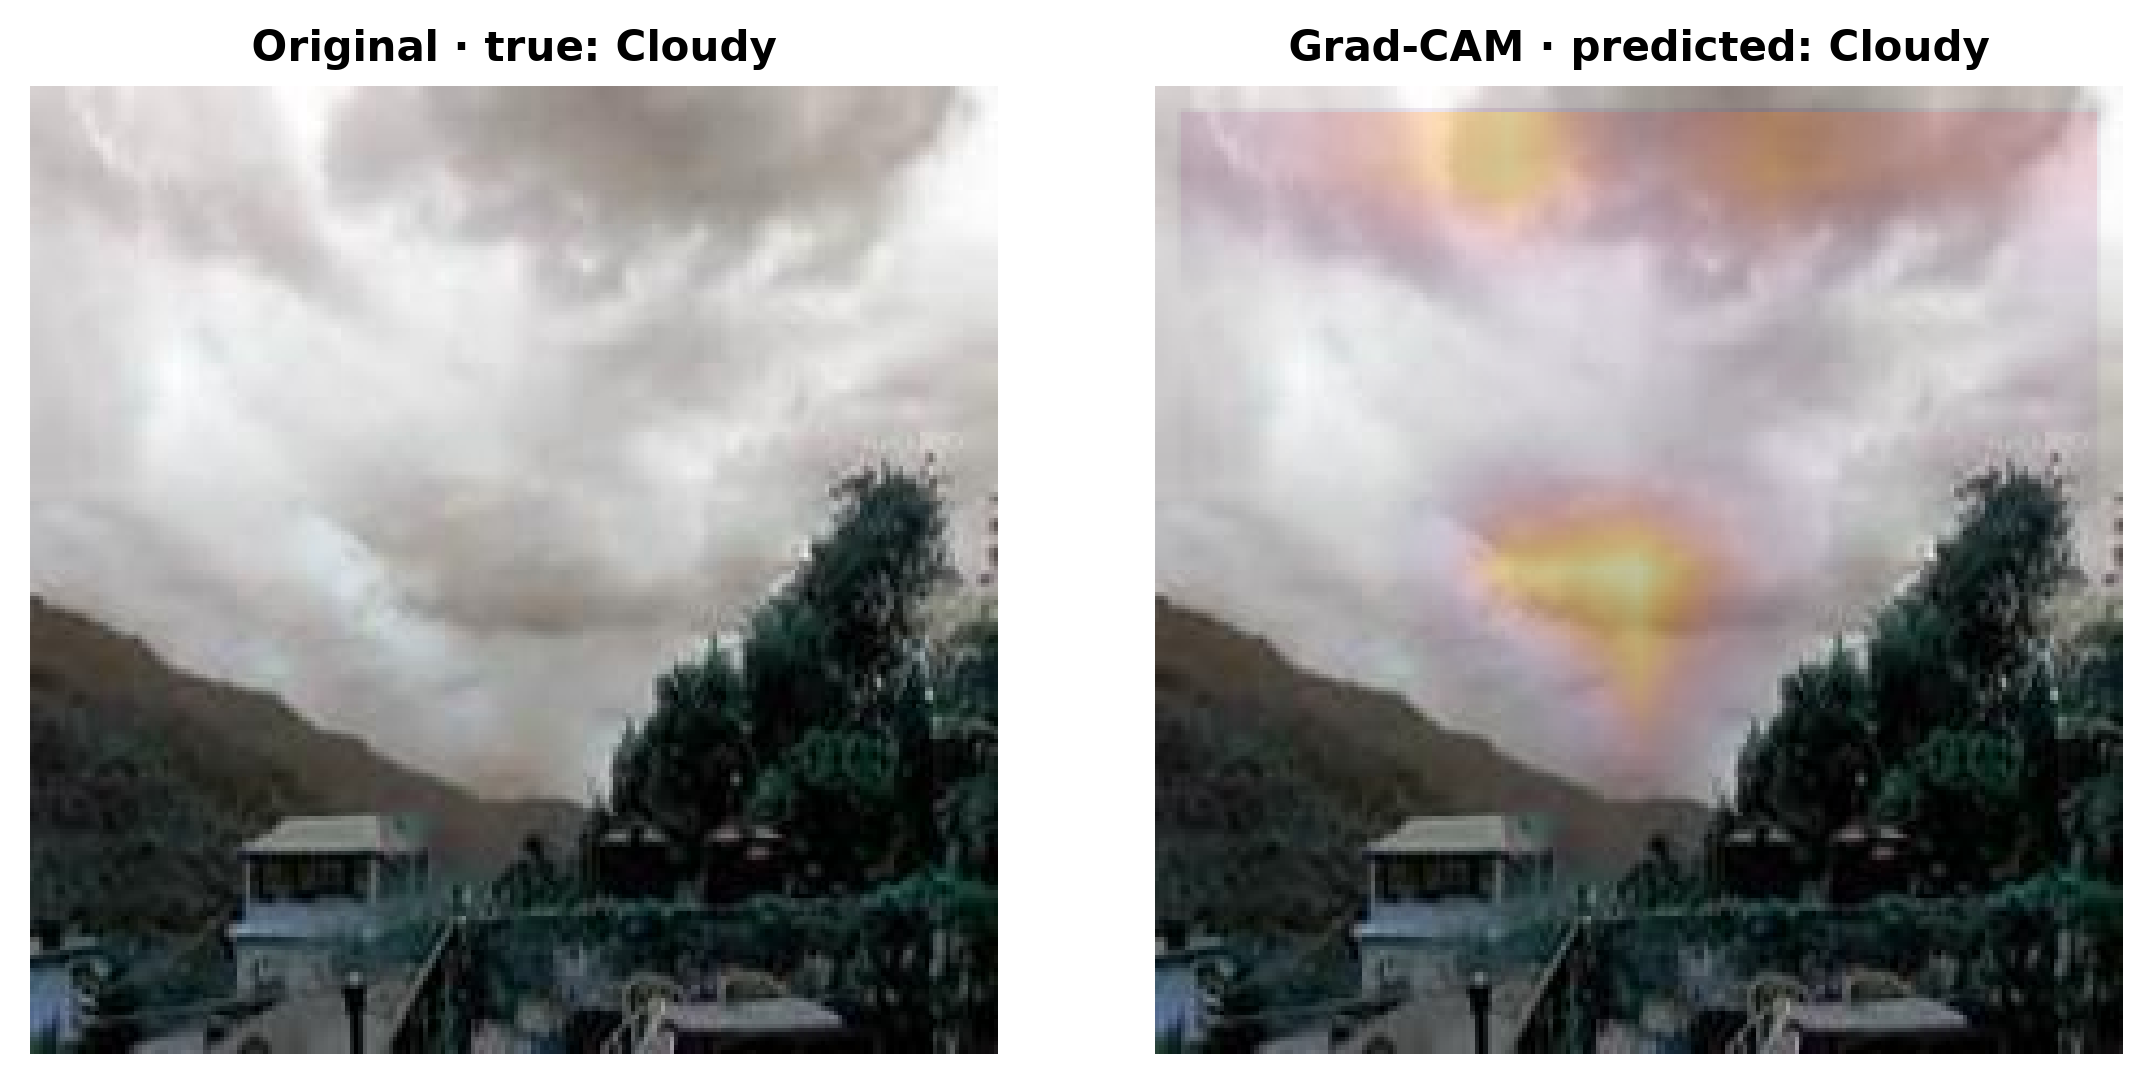

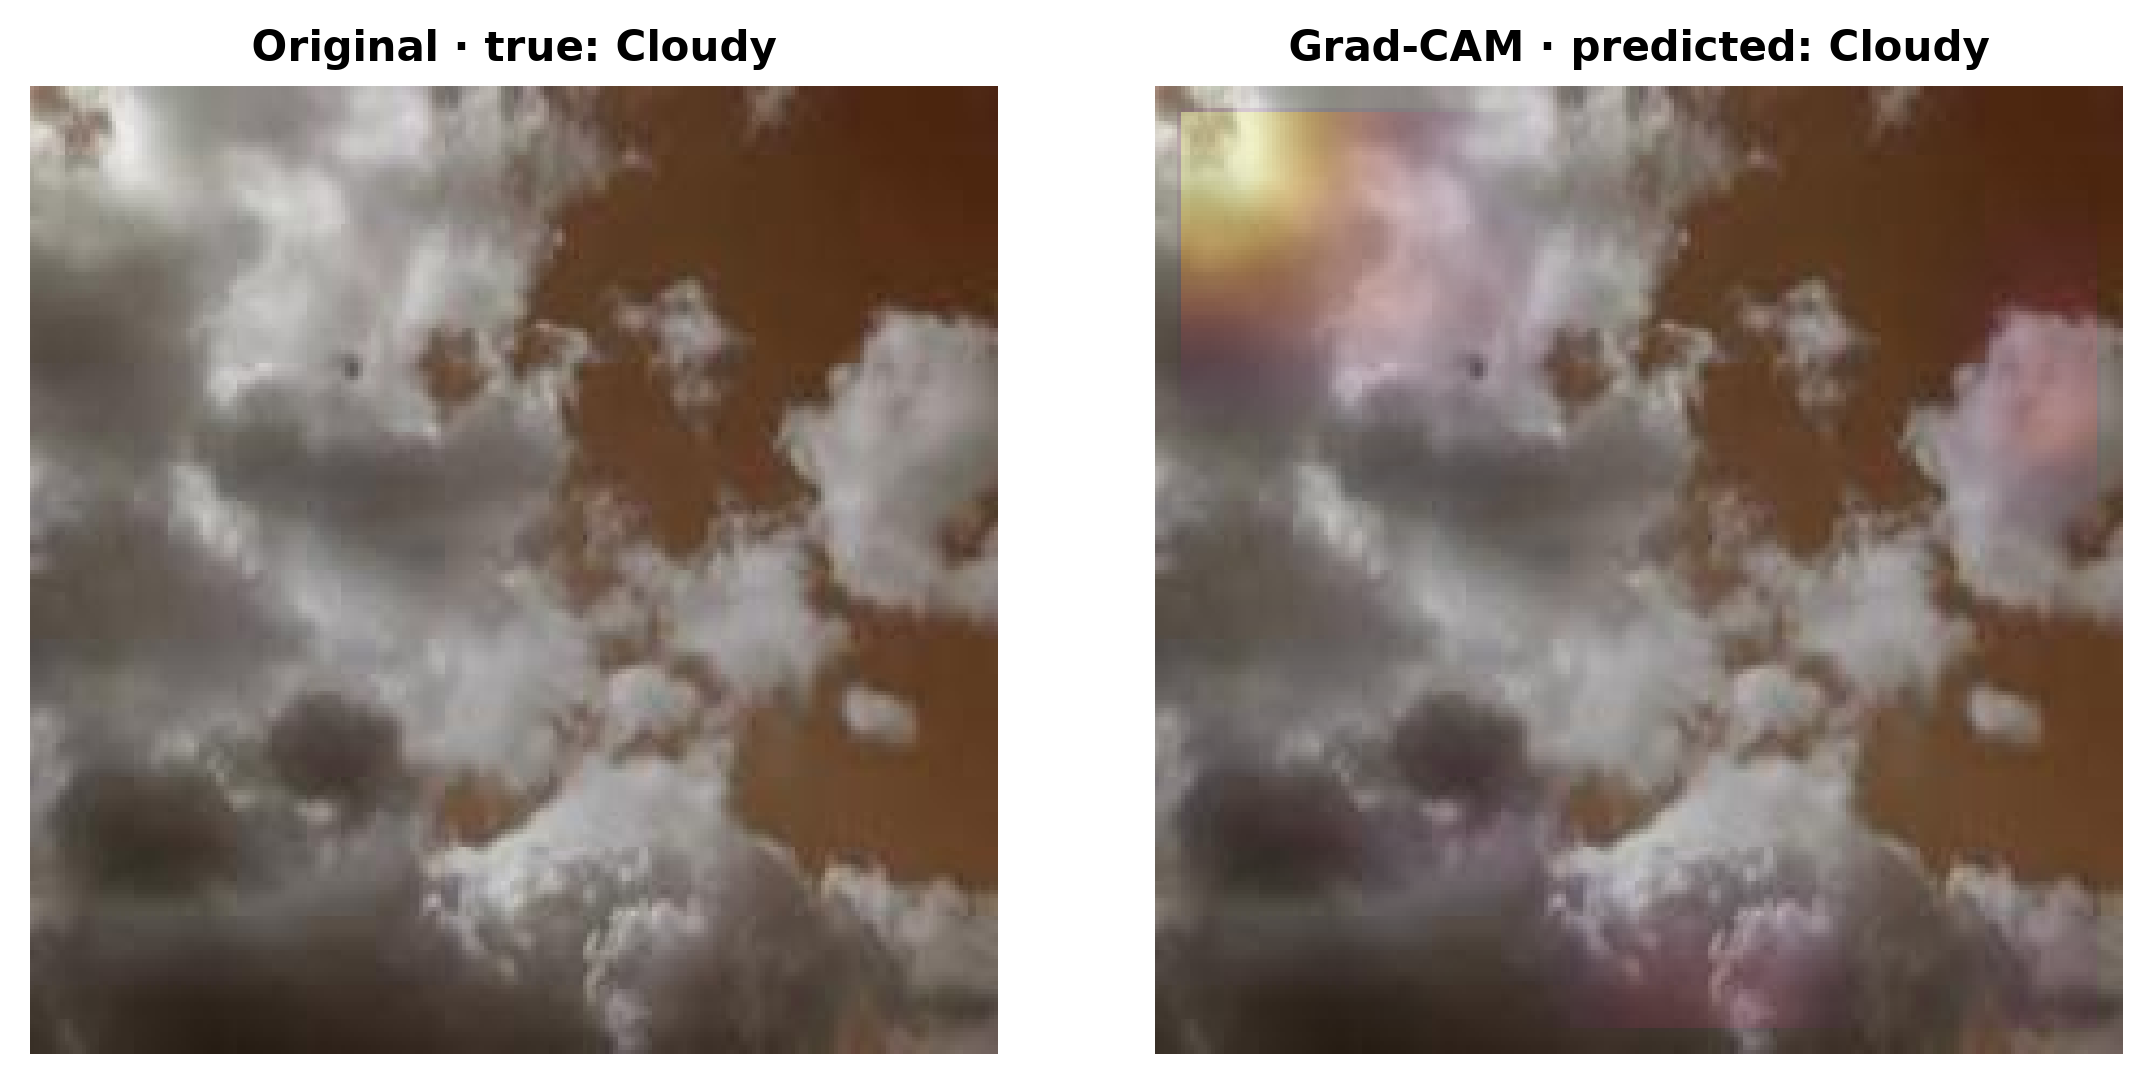

{
  "target_layer": "features[-1] (final spatial stage, before pooling)",
  "checkpoint_sha256": "0ed6e5c3912ccb2c60eddd2782a5d3322e4d5a7a5dcbb04a674fbcf3a43ae0ba",
  "examples": [
    {
      "figure": "gradcam_01.png",
      "path": "data/raw/Weather-Analysis-ad78ac8fcf1b1aae229ca6e5310aa75b06783787/cloud/cloud_267.jpeg",
      "true": "cloudy",
      "predicted": "sunrise",
      "correct": false,
      "heatmap_min": 0.0,
      "heatmap_max": 1.0
    },
    {
      "figure": "gradcam_02.png",
      "path": "data/raw/Weather-Analysis-ad78ac8fcf1b1aae229ca6e5310aa75b06783787/rain/rain_209.jpeg",
      "true": "rain",
      "predicted": "sunrise",
      "correct": false,
      "heatmap_min": 0.0,
      "heatmap_max": 1.0
    },
    {
      "figure": "gradcam_03.png",
      "path": "data/raw/Weather-Analysis-ad78ac8fcf1b1aae229ca6e5310aa75b06783787/shine/shine_1.jpeg",
      "true": "shine",
      "predicted": "sunrise",
      "correct": false,
      "heatmap_min": 0.0,
      "heatmap_

In [13]:
if not Path('outputs/convnext_aug/gradcam_metadata.json').exists():
    cli('explain', '--run', 'convnext_aug', '--count', 6)
for figure in sorted(Path('outputs/convnext_aug').glob('gradcam_*.png')):
    display(IPImage(filename=str(figure), width=800))
print(Path('outputs/convnext_aug/gradcam_metadata.json').read_text())

## 14. Generate reports from real stored outputs

Produces an eight-page Assignment 2 report and five-page Assignment 1 report using the saved metrics, figures, and author details from `configs/submission.yaml`. Rebuild reports after changing experiments.

In [14]:
subprocess.run([sys.executable, 'scripts/build_reports.py'], check=True)

COMPLETE MEASURED EXPERIMENTS {'assignment1_foundation': 5, 'assignment2_report': 8}


CompletedProcess(args=['/Users/rakhman/Desktop/assignment2-cv/.venv/bin/python', 'scripts/build_reports.py'], returncode=0)

## 15. Export checkpoints, results, and reports

Keep `best.pt` for deployment and `last.pt` to resume. Full checkpoints include the frozen backbone. The export also contains the manifest and audit, and source references. Data images and cached pretrained weights are not included. Save the archive to Drive for persistence before a Colab runtime resets.

In [15]:
import shutil
EXPORT = Path('/content/WeatherVision_results.zip') if Path('/content').exists() else PROJECT / 'dist/WeatherVision_results.zip'
EXPORT.parent.mkdir(parents=True, exist_ok=True)
BUILD_RESULTS_ARCHIVE = Path('/content').exists()
if BUILD_RESULTS_ARCHIVE:
    subprocess.run([sys.executable, 'scripts/package_project.py', '--results'], check=True)
    if EXPORT.resolve() != Path('dist/WeatherVision_results.zip').resolve():
        shutil.copy2('dist/WeatherVision_results.zip', EXPORT)
    print(EXPORT)
else:
    print('Local execution: checkpoints and results retained in outputs/. Archive creation is optional.')
SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE and BUILD_RESULTS_ARCHIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    destination = Path('/content/drive/MyDrive/WeatherVision')
    destination.mkdir(parents=True, exist_ok=True)
    shutil.copy2(EXPORT, destination / EXPORT.name)
DOWNLOAD = True
if DOWNLOAD and BUILD_RESULTS_ARCHIVE:
    from google.colab import files
    files.download(str(EXPORT))

Local execution: checkpoints and results retained in outputs/. Archive creation is optional.


## 16. Run the local application and prepare submission

Extract the results ZIP inside the local project, preserving `outputs/` and `data/`. Prepare the pinned dataset locally if real examples are desired. Then:

```bash
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

The application reads trained checkpoints; it never trains at launch. Use `docs/DEFENSE_GUIDE.md` and `docs/DEMO_SCRIPT.md` to prepare a 3-5 minute presentation. Deadline: **November 7, 2026, 23:59 Asia/Almaty**.